# **TALLER 1 DE REDES NEURONALES: CLASIFICACIÓN BINARIA**

**Asignatura:** Redes Neuronales Cod. 167310

**Docente:** Ing. Jeisson Martínez Flórez

**Semestre:** 2026-2

**Programa:** Ingeniería Mecatrónica

**Sede:** Villa del Rosario - Unipamplona


---
## **Identificación del Estudiante**

Por favor, a continuación coloque sus datos:

* **Nombres:** Jeisson
* **Apellidos:** Martinez
* **Código de Identificación:** 11111


---
## Desarrollo del Taller

En esta actividad vamos a utilizar una red neuronal para resolver un problema de **clasificación binaria**. El objetivo es predecir, por ejemplo, si un cliente o empleado abandonará una empresa (churn), si un cliente comprará un producto, o cualquier otro problema con una salida de dos posibles categorías (Sí/No, 1/0, Verdadero/Falso).

Utilizaremos **Keras con TensorFlow** para construir, entrenar y evaluar nuestro modelo.

El código utilizado para contestar tiene que quedar claramente reflejado en el Notebook. Puedes crear nuevas celdas si así lo deseas para estructurar tu código y sus salidas. A la hora de entregar el notebook, **asegúrate de que los resultados de ejecutar tu código han quedado guardados**.

### **Elección del Dataset**

En clase, serán sorteados los siguientes 12 datasets en donde solo **uno** de ellos te corresponderá. Debes ingresar a la plataforma Kaggle y descargar el dataset en .CSV para poder utilizarlo en este notebook.

Datasets:
1. **Bank Customer Churn Prediction:**
Contiene datos demográficos y transaccionales de clientes de un banco. El objetivo es predecir si un cliente abandonará (`Exited`) el banco, ayudando a la entidad a diseñar estrategias de retención de manera proactiva.
[Link](https://www.kaggle.com/datasets/shantanudhakadd/bank-customer-churn-prediction)


2. **IBM HR Analytics Employee Attrition:**
Este dataset de IBM incluye información sobre los empleados, como su rol, nivel de satisfacción y datos demográficos. El objetivo es predecir la deserción (`Attrition`), es decir, si un empleado dejará la empresa o no.
[Link](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)

3. **Credit Card Customers:**
Contiene datos de clientes de tarjetas de crédito, incluyendo límites de crédito, gastos y datos demográficos. El objetivo es predecir qué clientes probablemente cancelarán su servicio (`Attrition_Flag`), permitiendo tomar acciones para retenerlos.
[Link](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers)

4. **Bank Marketing Dataset:**
Recopila información de campañas de marketing de un banco portugués. El objetivo es predecir si un cliente se suscribirá (`y`) a un depósito a plazo después de ser contactado, optimizando así los esfuerzos de marketing.
[Link](https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset)

5. **Default of Credit Card Clients Dataset:**
Incluye información sobre clientes de tarjetas de crédito en Taiwán, con datos demográficos y su historial de pagos. El objetivo es predecir si un cliente incumplirá (`default.payment.next.month`) su pago el próximo mes.
[Link](https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset)

6. **E-commerce Customer Churn:**
Contiene datos sobre el comportamiento de los clientes en una plataforma de comercio electrónico. El objetivo es predecir el abandono de clientes (`Churn`), identificando a aquellos en riesgo de dejar de usar el servicio.
[Link](https://www.kaggle.com/datasets/samuelsemaya/e-commerce-customer-churn)

7. **Online Shoppers Intention:**
Registra el comportamiento de los visitantes de un sitio web de compras en línea. El objetivo es predecir si una sesión de navegación terminará en una compra (`Revenue`), ayudando a optimizar la experiencia del usuario.
[Link](https://www.kaggle.com/datasets/henrysue/online-shoppers-intention)

8. **Customer Personality Analysis:**
Describe los perfiles de los clientes a través de sus datos demográficos y hábitos de compra. El objetivo es predecir si un cliente responderá (`Response`) afirmativamente a una campaña de marketing.
[Link](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis)

9. **Loan Predication:**
Contiene información de solicitantes de préstamos. El objetivo es predecir si una solicitud de préstamo será aprobada (`Loan_Status`) o no, basándose en el perfil del solicitante como historial de crédito e ingresos.
[Link](https://www.kaggle.com/datasets/ninzaami/loan-predication)

10. **Airline Passenger Satisfaction:**
Recopila encuestas de satisfacción de pasajeros de una aerolínea. El objetivo es predecir si un pasajero está satisfecho (`satisfaction`) o no, a partir de factores como la comodidad del asiento, el servicio a bordo y la puntualidad.
[Link](https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction)

11. **Stroke Prediction Dataset:**
Incluye datos demográficos y de salud de pacientes. El objetivo es predecir si un paciente es propenso a sufrir un accidente cerebrovascular (`stroke`), lo que permite identificar individuos de alto riesgo para una intervención temprana.
[Link](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset)

12. **Health Insurance Cross Sell Prediction:**
Contiene información de clientes de una compañía de seguros de salud. El objetivo es predecir si un cliente existente estaría interesado (`Response`) en adquirir un seguro de vehículos, optimizando las campañas de venta cruzada.
[Link](https://www.kaggle.com/datasets/anmolkumar/health-insurance-cross-sell-prediction/data)

### **Carga de Librerías y Datos**
El primer paso es importar las librerías que necesitaremos y cargar el dataset asignado en un DataFrame de Pandas.

In [5]:
# ===== Carga de Librerías y Datos =====
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

# Carga del dataset asignado (hotels.csv = H1 + H2 unidos)
df = pd.read_csv('../dataset/hotels.csv')

# Nombres de columnas en español (los valores no cambian)
nombres_es = {
    'hotel': 'hotel',
    'is_canceled': 'es_cancelado',
    'lead_time': 'dias_anticipacion',
    'arrival_date_year': 'anio_llegada',
    'arrival_date_month': 'mes_llegada',
    'arrival_date_week_number': 'semana_llegada',
    'arrival_date_day_of_month': 'dia_llegada',
    'stays_in_weekend_nights': 'noches_fin_semana',
    'stays_in_week_nights': 'noches_entre_semana',
    'adults': 'adultos',
    'children': 'ninos',
    'babies': 'bebes',
    'meal': 'comida',
    'country': 'pais',
    'market_segment': 'segmento_mercado',
    'distribution_channel': 'canal_distribucion',
    'is_repeated_guest': 'es_huesped_repetido',
    'previous_cancellations': 'cancelaciones_previas',
    'previous_bookings_not_canceled': 'reservas_previas_no_canceladas',
    'reserved_room_type': 'tipo_habitacion_reservada',
    'assigned_room_type': 'tipo_habitacion_asignada',
    'booking_changes': 'cambios_reserva',
    'deposit_type': 'tipo_deposito',
    'agent': 'agente',
    'company': 'empresa',
    'days_in_waiting_list': 'dias_lista_espera',
    'customer_type': 'tipo_cliente',
    'adr': 'tarifa_diaria',
    'required_car_parking_spaces': 'espacios_parqueadero',
    'total_of_special_requests': 'solicitudes_especiales',
    'reservation_status': 'estado_reserva',
    'reservation_status_date': 'fecha_estado_reserva',
}
df = df.rename(columns=nombres_es)

# Variable objetivo (1 = canceló, 0 = no canceló)
objetivo = 'es_cancelado'

# Copia del original por si hay que volver atrás
df_raw = df.copy()

# Verificación
df.head(15)

,hotel,es_cancelado,dias_anticipacion,anio_llegada,mes_llegada,semana_llegada,dia_llegada,noches_fin_semana,noches_entre_semana,adultos,ninos,bebes,comida,pais,segmento_mercado,canal_distribucion,es_huesped_repetido,cancelaciones_previas,reservas_previas_no_canceladas,tipo_habitacion_reservada,tipo_habitacion_asignada,cambios_reserva,tipo_deposito,agente,empresa,dias_lista_espera,tipo_cliente,tarifa_diaria,espacios_parqueadero,solicitudes_especiales,estado_reserva,fecha_estado_reserva
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,NaN,NaN,0,Transient,107.00,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,0.0,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,303.0,NaN,0,Transient,103.00,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,82.00,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,D,D,0,No Deposit,15.0,NaN,0,Transient,105.50,0,0,Canceled,2015-04-22


                                                                                    Analisis Previo del Dataset

In [3]:
print('========================================')
print('1. CALIDAD DE LOS DATOS')
print('========================================\n')

print('--- Cantidad de filas y columnas ---')
print(f'Número de filas: {df.shape[0]}')
print(f'Número de columnas: {df.shape[1]}')

print('\n--- Tipos de datos por columna ---')
print(df.dtypes.to_string())          # to_string evita que la salida se corte
print('\nResumen de tipos:')
print(df.dtypes.value_counts())

print('\n--- Conteo de valores nulos o NaN (solo columnas con nulos) ---')
nulos = df.isnull().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
print(pd.DataFrame({
    'nulos': nulos,
    'porcentaje_%': (nulos / len(df) * 100).round(2)
}))

print('\n--- Conteo de filas duplicadas ---')
print(f'Total de filas duplicadas: {df.duplicated().sum()}')
print(f'Porcentaje: {df.duplicated().mean() * 100:.1f} %')

1. CALIDAD DE LOS DATOS

--- Cantidad de filas y columnas ---
Número de filas: 119390
Número de columnas: 32

--- Tipos de datos por columna ---
hotel                              object
es_cancelado                        int64
dias_anticipacion                   int64
anio_llegada                        int64
mes_llegada                        object
semana_llegada                      int64
dia_llegada                         int64
noches_fin_semana                   int64
noches_entre_semana                 int64
adultos                             int64
ninos                             float64
bebes                               int64
comida                             object
pais                               object
segmento_mercado                   object
canal_distribucion                 object
es_huesped_repetido                 int64
cancelaciones_previas               int64
reservas_previas_no_canceladas      int64
tipo_habitacion_reservada          object
tipo_habitacion

3. SIGNIFICADO VS. TARGET

Tasa global de cancelación: 37.0%

--- 3.1 Correlación de las numéricas con es_cancelado ---
dias_anticipacion                 0.293
solicitudes_especiales           -0.235
espacios_parqueadero             -0.195
cambios_reserva                  -0.144
cancelaciones_previas             0.110
es_huesped_repetido              -0.085
adultos                           0.060
reservas_previas_no_canceladas   -0.057
dias_lista_espera                 0.054
tarifa_diaria                     0.048
bebes                            -0.032
noches_entre_semana               0.025
anio_llegada                      0.017
semana_llegada                    0.008
dia_llegada                      -0.006
ninos                             0.005
noches_fin_semana                -0.002


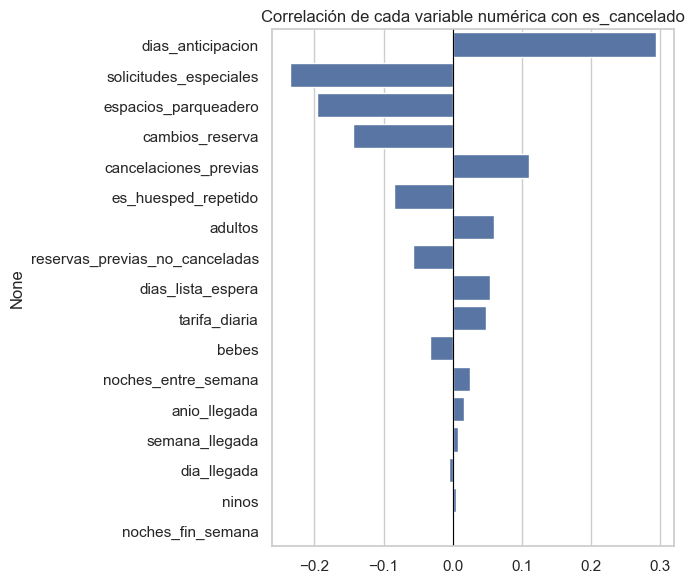


--- 3.2 Tamaño del efecto (d de Cohen) ---
dias_anticipacion                 0.635
solicitudes_especiales           -0.500
espacios_parqueadero             -0.413
cambios_reserva                  -0.302
cancelaciones_previas             0.229
es_huesped_repetido              -0.176
adultos                           0.125
reservas_previas_no_canceladas   -0.119
dias_lista_espera                 0.112
tarifa_diaria                     0.099
bebes                            -0.067
noches_entre_semana               0.051
anio_llegada                      0.035
semana_llegada                    0.017
dia_llegada                      -0.013
ninos                             0.010
noches_fin_semana                -0.004
(|d| < 0.2 despreciable, 0.2-0.5 pequeño, 0.5-0.8 mediano, > 0.8 grande)

--- 3.3 Distribución por clase de las numéricas más relevantes ---


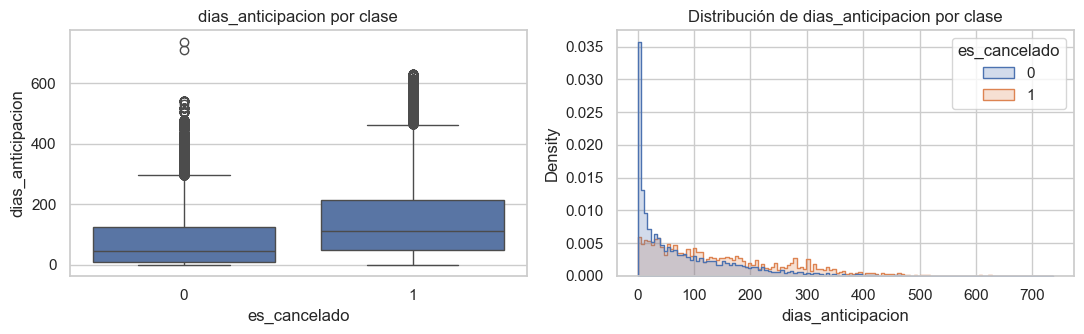

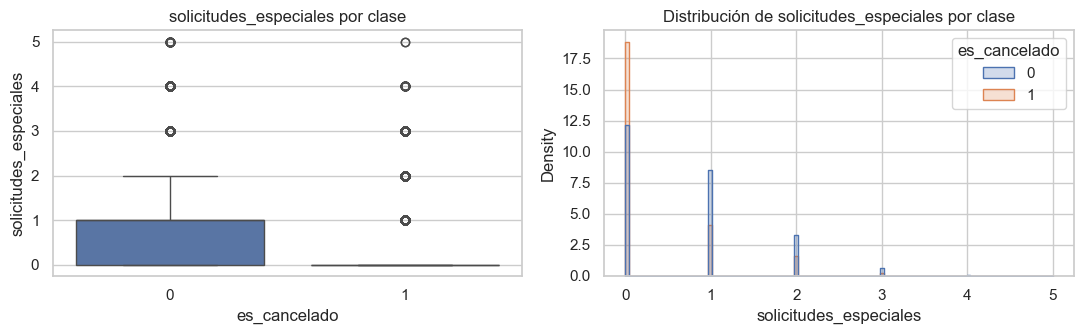

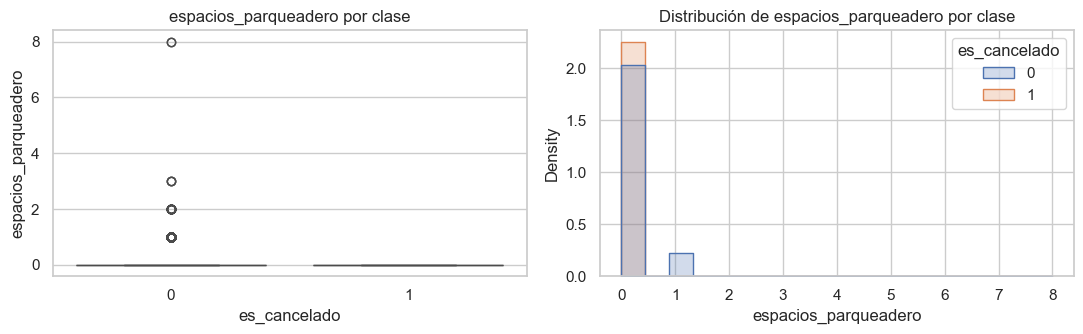

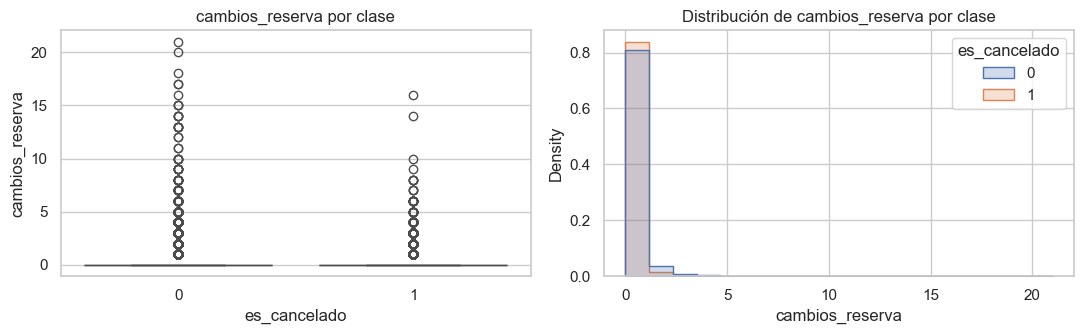


--- 3.4 Tasa de cancelación por categoría ---


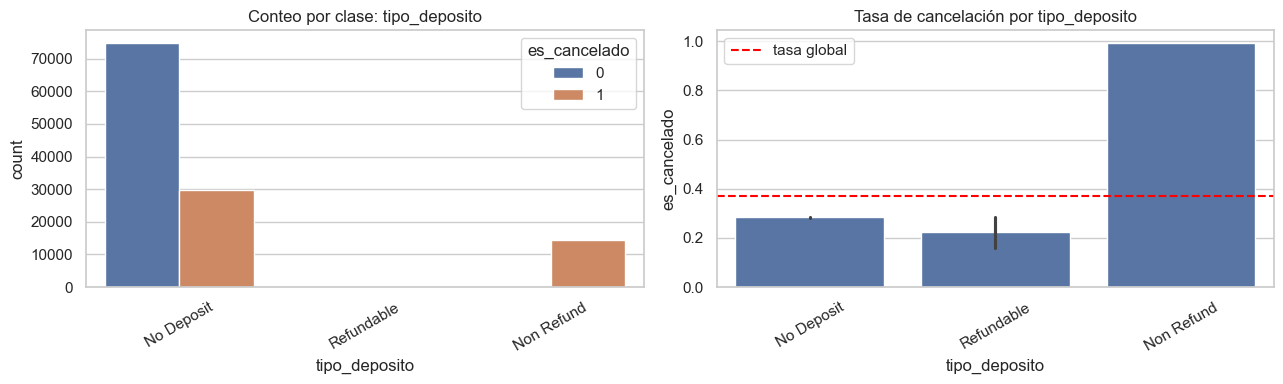

               reservas  tasa_cancelacion
tipo_deposito                            
No Deposit       104641             0.284
Non Refund        14587             0.994
Refundable          162             0.222 



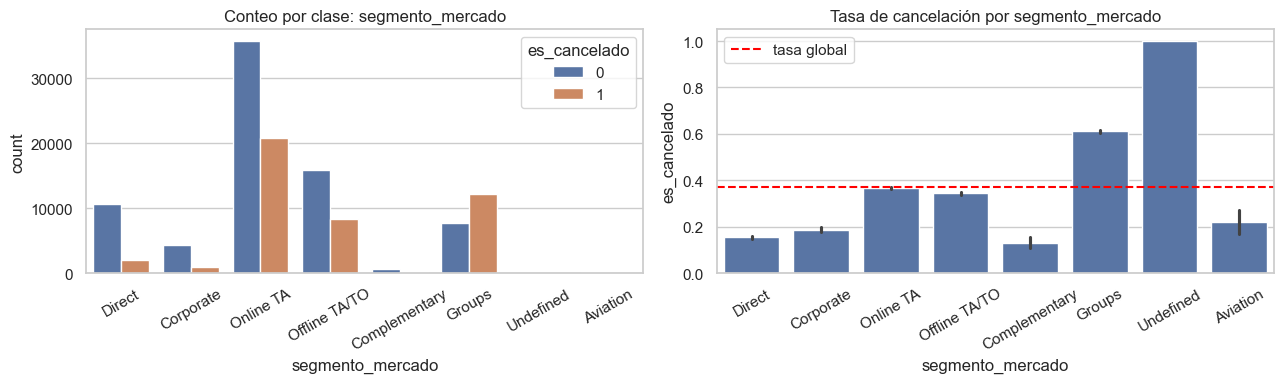

                  reservas  tasa_cancelacion
segmento_mercado                            
Aviation               237             0.219
Complementary          743             0.131
Corporate             5295             0.187
Direct               12606             0.153
Groups               19811             0.611
Offline TA/TO        24219             0.343
Online TA            56477             0.367
Undefined                2             1.000 



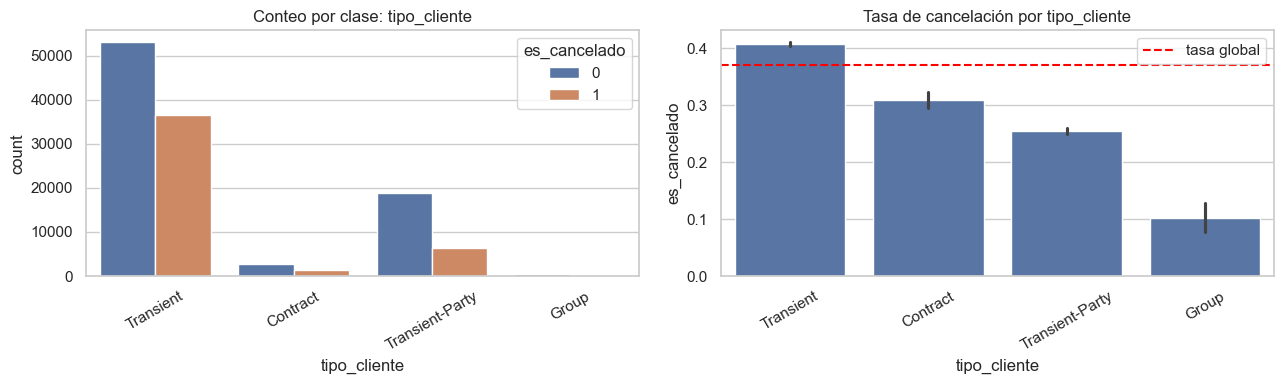

                 reservas  tasa_cancelacion
tipo_cliente                               
Contract             4076             0.310
Group                 577             0.102
Transient           89613             0.407
Transient-Party     25124             0.254 



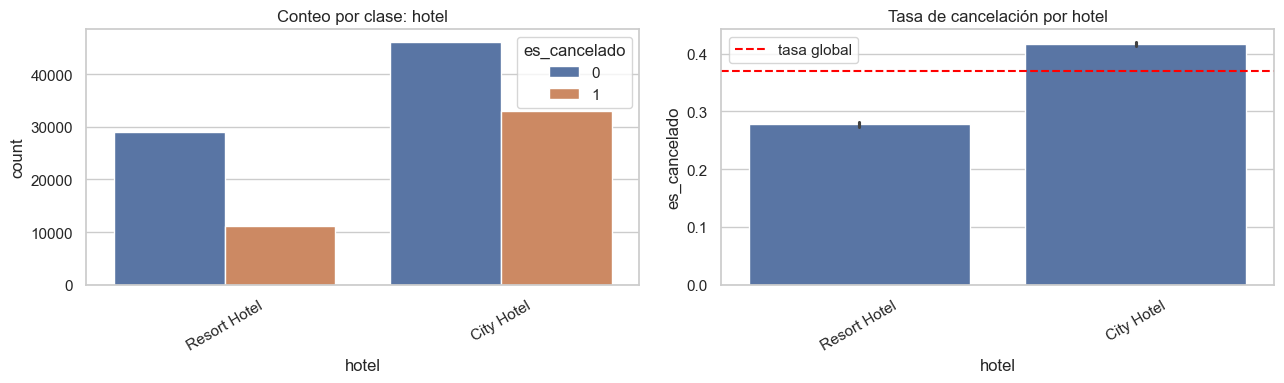

              reservas  tasa_cancelacion
hotel                                   
City Hotel       79330             0.417
Resort Hotel     40060             0.278 

--- 3.5 V de Cramér de las categóricas con es_cancelado ---
                 variable  V_cramer  p_valor
            tipo_deposito     0.481      0.0
                     pais     0.361      0.0
         segmento_mercado     0.267      0.0
 tipo_habitacion_asignada     0.203      0.0
       canal_distribucion     0.177      0.0
                    hotel     0.137      0.0
             tipo_cliente     0.136      0.0
tipo_habitacion_reservada     0.074      0.0
              mes_llegada     0.070      0.0
                   comida     0.050      0.0
(< 0.10 despreciable, 0.10-0.20 débil, 0.20-0.40 moderada, > 0.40 fuerte)

--- 3.6 Ranking global (información mutua) ---
tipo_deposito                     0.1311
dias_anticipacion                 0.0854
tarifa_diaria                     0.0764
pais                              

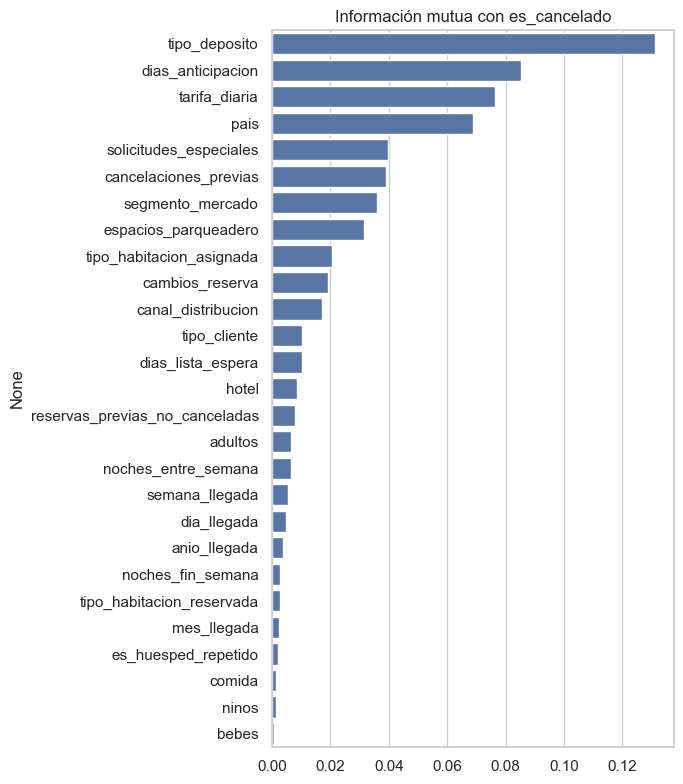


--- 3.7 Posible fuga de información: estado_reserva vs. es_cancelado ---
es_cancelado      0    1
estado_reserva          
Canceled        0.0  1.0
Check-Out       1.0  0.0
No-Show         0.0  1.0


In [8]:
# ==========================================================
# 3. SIGNIFICADO VS. TARGET (qué tan predictoras son las variables)
# ==========================================================
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif

print('========================================')
print('3. SIGNIFICADO VS. TARGET')
print('========================================\n')

# ---------- Listas de columnas ----------
num_cols = ['dias_anticipacion', 'anio_llegada', 'semana_llegada', 'dia_llegada',
            'noches_fin_semana', 'noches_entre_semana', 'adultos', 'ninos', 'bebes',
            'es_huesped_repetido', 'cancelaciones_previas', 'reservas_previas_no_canceladas',
            'cambios_reserva', 'dias_lista_espera', 'tarifa_diaria',
            'espacios_parqueadero', 'solicitudes_especiales']

cat_cols = ['hotel', 'mes_llegada', 'comida', 'pais', 'segmento_mercado',
            'canal_distribucion', 'tipo_habitacion_reservada', 'tipo_habitacion_asignada',
            'tipo_deposito', 'tipo_cliente']

tasa_global = df[objetivo].mean()
print(f'Tasa global de cancelación: {tasa_global:.1%}')

# ---------- 3.1 Numéricas vs. objetivo: correlación ----------
print('\n--- 3.1 Correlación de las numéricas con es_cancelado ---')
corr_obj = df[num_cols].corrwith(df[objetivo]).sort_values(key=abs, ascending=False)
print(corr_obj.round(3).to_string())

plt.figure(figsize=(7, 6))
sns.barplot(x=corr_obj.values, y=corr_obj.index, orient='h')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlación de cada variable numérica con es_cancelado')
plt.tight_layout()
plt.show()

# ---------- 3.2 Tamaño del efecto (d de Cohen) ----------
print('\n--- 3.2 Tamaño del efecto (d de Cohen) ---')
def d_cohen(x0, x1):
    n0, n1 = len(x0), len(x1)
    s = np.sqrt(((n0 - 1) * x0.var() + (n1 - 1) * x1.var()) / (n0 + n1 - 2))
    return (x1.mean() - x0.mean()) / s

efectos = {c: d_cohen(df.loc[df[objetivo] == 0, c].dropna(),
                      df.loc[df[objetivo] == 1, c].dropna()) for c in num_cols}
print(pd.Series(efectos).sort_values(key=abs, ascending=False).round(3).to_string())
print('(|d| < 0.2 despreciable, 0.2-0.5 pequeño, 0.5-0.8 mediano, > 0.8 grande)')

# ---------- 3.3 Distribución por clase de las 4 numéricas más relevantes ----------
print('\n--- 3.3 Distribución por clase de las numéricas más relevantes ---')
top_num = corr_obj.abs().sort_values(ascending=False).head(4).index.tolist()
for c in top_num:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    sns.boxplot(data=df, x=objetivo, y=c, ax=ax1)
    ax1.set_title(f'{c} por clase')
    sns.histplot(data=df, x=c, hue=objetivo, stat='density', common_norm=False,
                 element='step', ax=ax2)
    ax2.set_title(f'Distribución de {c} por clase')
    plt.tight_layout()
    plt.show()

# ---------- 3.4 Categóricas vs. objetivo: tasa de cancelación ----------
print('\n--- 3.4 Tasa de cancelación por categoría ---')
for c in ['tipo_deposito', 'segmento_mercado', 'tipo_cliente', 'hotel']:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    sns.countplot(data=df, x=c, hue=objetivo, ax=axes[0])
    axes[0].set_title(f'Conteo por clase: {c}')
    sns.barplot(data=df, x=c, y=objetivo, ax=axes[1])
    axes[1].axhline(tasa_global, color='red', linestyle='--', label='tasa global')
    axes[1].set_title(f'Tasa de cancelación por {c}')
    axes[1].legend()
    for ax in axes:
        ax.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    plt.show()

    print(df.groupby(c)[objetivo].agg(['size', 'mean']).round(3)
            .rename(columns={'size': 'reservas', 'mean': 'tasa_cancelacion'}), '\n')

# ---------- 3.5 V de Cramér (fuerza de asociación de las categóricas) ----------
print('--- 3.5 V de Cramér de las categóricas con es_cancelado ---')
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2, p, gl, _ = chi2_contingency(tabla, correction=False)
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    return np.sqrt(chi2 / (n * k)), p

resultados = []
for c in cat_cols:
    v, p = cramers_v(df[c].fillna('faltante'), df[objetivo])
    resultados.append({'variable': c, 'V_cramer': round(v, 3), 'p_valor': round(p, 4)})
print(pd.DataFrame(resultados).sort_values('V_cramer', ascending=False).to_string(index=False))
print('(< 0.10 despreciable, 0.10-0.20 débil, 0.20-0.40 moderada, > 0.40 fuerte)')

# ---------- 3.6 Ranking global: información mutua ----------
print('\n--- 3.6 Ranking global (información mutua) ---')
X_tmp = df[num_cols + cat_cols].copy()
for c in cat_cols:
    X_tmp[c] = X_tmp[c].astype('category').cat.codes
X_tmp = X_tmp.fillna(X_tmp.median())

es_cat = [c in cat_cols for c in X_tmp.columns]
muestra = X_tmp.sample(50000, random_state=0)          # muestra para que sea rápido
mi = mutual_info_classif(muestra, df.loc[muestra.index, objetivo],
                         discrete_features=es_cat, random_state=0)
mi = pd.Series(mi, index=X_tmp.columns).sort_values(ascending=False)
print(mi.round(4).to_string())

plt.figure(figsize=(7, 8))
sns.barplot(x=mi.values, y=mi.index, orient='h')
plt.title('Información mutua con es_cancelado')
plt.tight_layout()
plt.show()

# ---------- 3.7 Variables que "delatan" la respuesta (fuga) ----------
print('\n--- 3.7 Posible fuga de información: estado_reserva vs. es_cancelado ---')
print(pd.crosstab(df['estado_reserva'], df[objetivo], normalize='index').round(3))

2. ESTADÍSTICAS

--- 2.1 Estadísticos de las variables numéricas ---


,count,mean,std,min,25%,50%,75%,max,mediana,IQR,asimetria,curtosis,ceros_%
dias_anticipacion,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0,69.00,142.00,1.35,1.70,5.3
anio_llegada,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0,2016.00,1.00,-0.23,-0.99,0.0
semana_llegada,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0,28.00,22.00,-0.01,-0.99,0.0
dia_llegada,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0,16.00,15.00,-0.00,-1.19,0.0
noches_fin_semana,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0,1.00,2.00,1.38,7.17,43.6
noches_entre_semana,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0,2.00,2.00,2.86,24.28,6.4
adultos,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0,2.00,0.00,18.32,1352.12,0.3
ninos,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0,0.00,0.00,4.11,18.67,92.8
bebes,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0,0.00,0.00,24.65,1633.95,99.2
es_huesped_repetido,119390.0,0.03,0.18,0.00,0.00,0.00,0.0,1.0,0.00,0.00,5.33,26.37,96.8



--- 2.2 Variables categóricas: categorías, moda y dominancia ---
                 variable  categorias       moda  dominancia_%
                    hotel           2 City Hotel          66.4
              mes_llegada          12     August          11.6
                   comida           5         BB          77.3
                     pais         177        PRT          40.9
         segmento_mercado           8  Online TA          47.3
       canal_distribucion           5      TA/TO          82.0
tipo_habitacion_reservada          10          A          72.0
 tipo_habitacion_asignada          12          A          62.0
            tipo_deposito           3 No Deposit          87.6
             tipo_cliente           4  Transient          75.1

--- Frecuencias de algunas categóricas clave ---

hotel:
              frecuencia  porcentaje_%
hotel                                 
City Hotel         79330         66.45
Resort Hotel       40060         33.55

tipo_deposito:
           

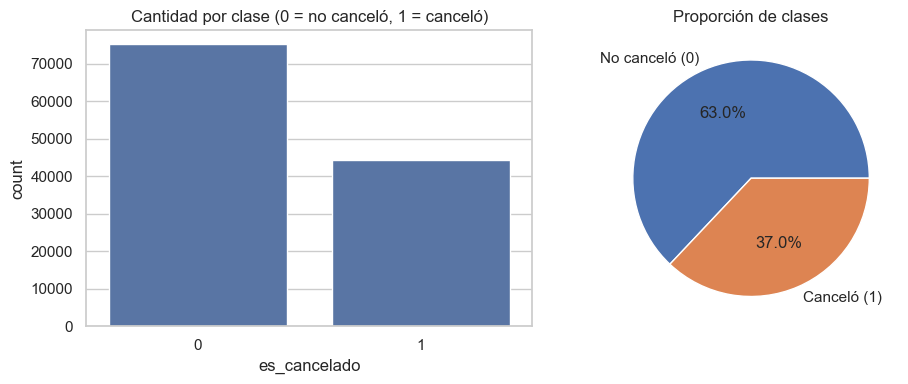

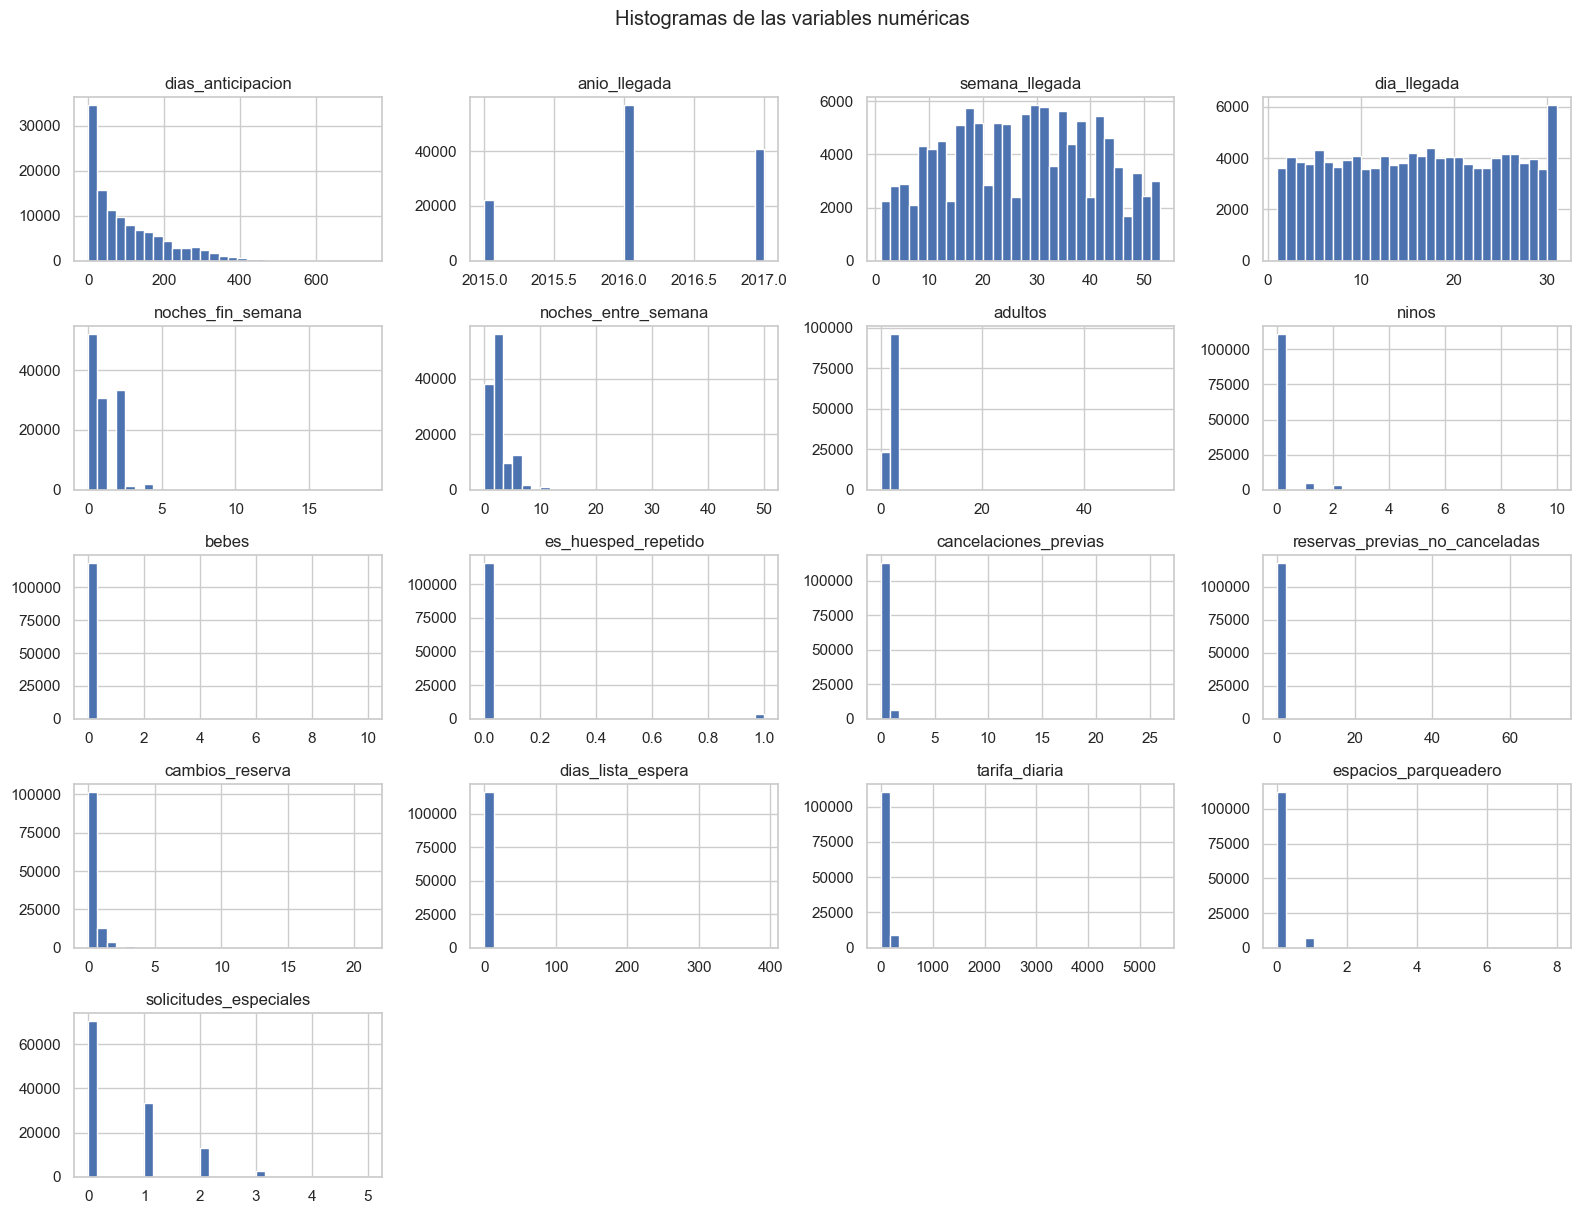

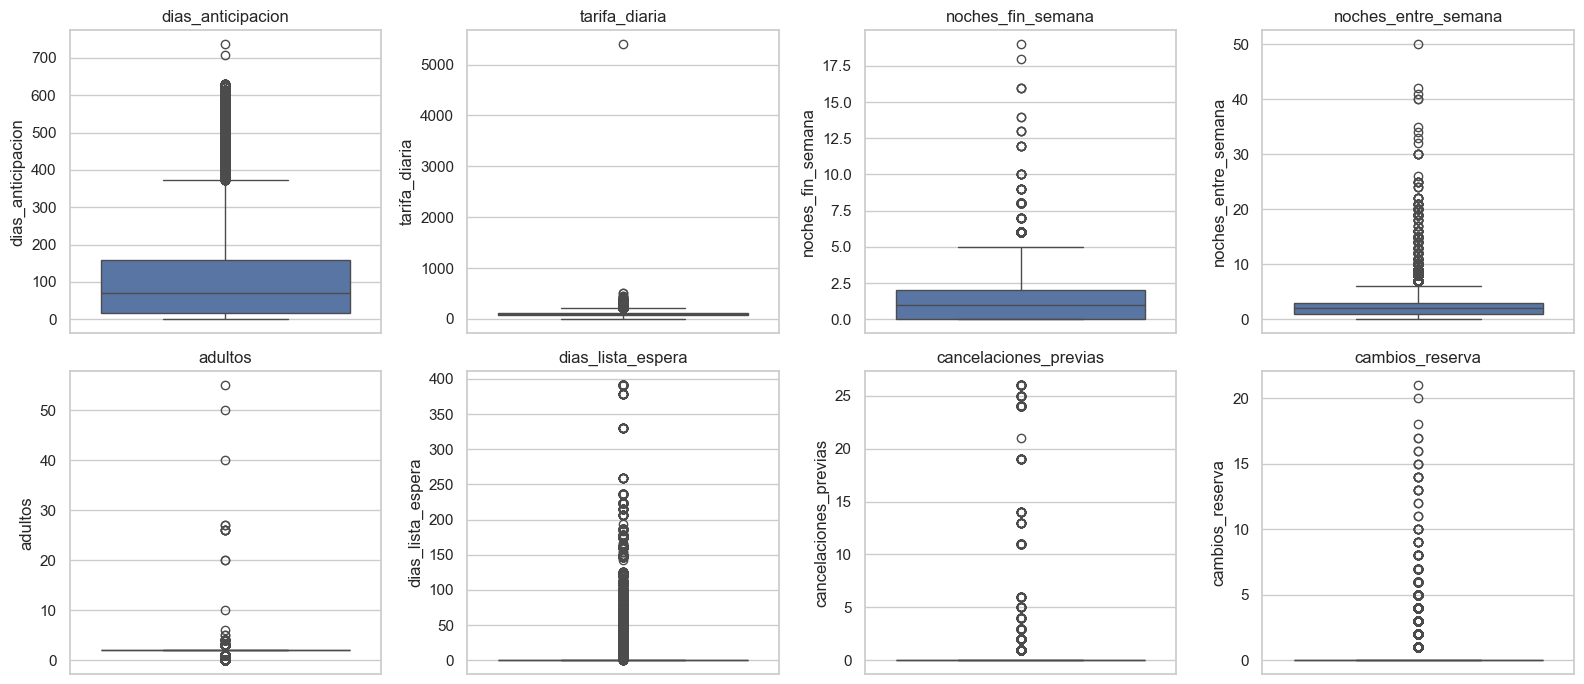

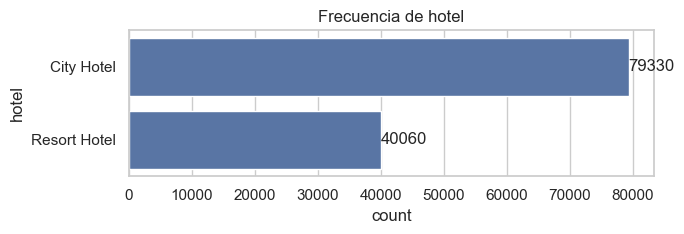

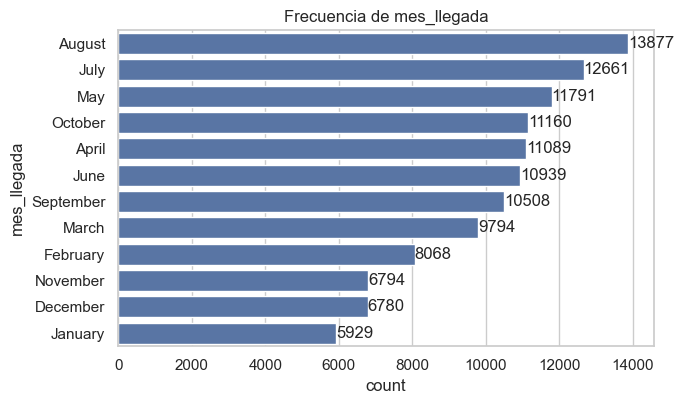

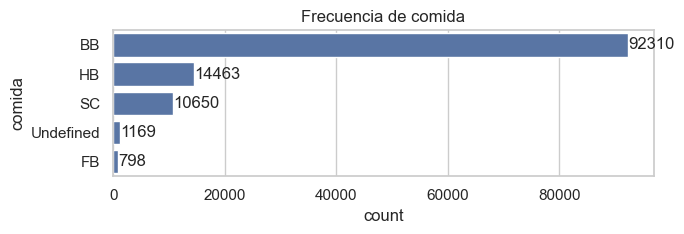

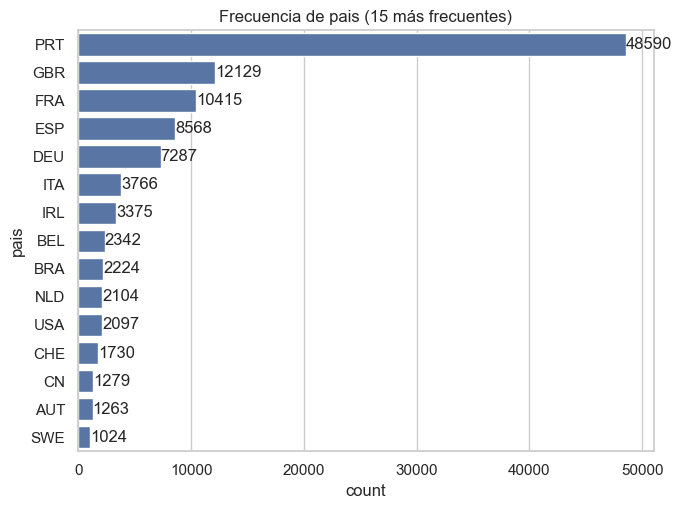

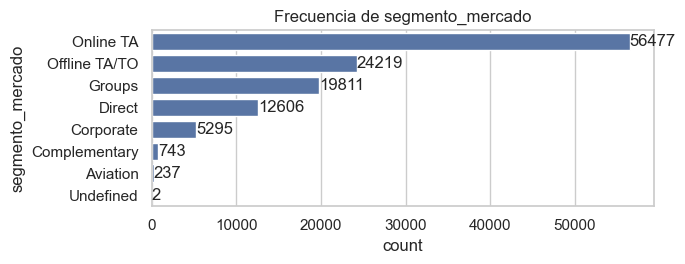

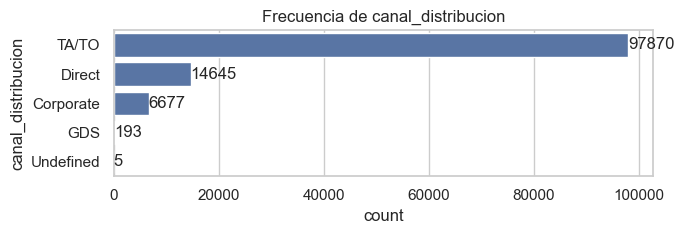

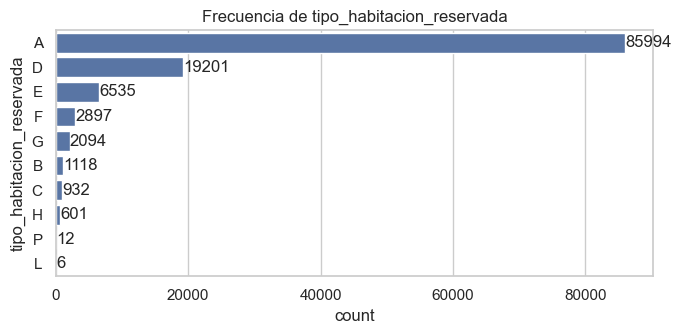

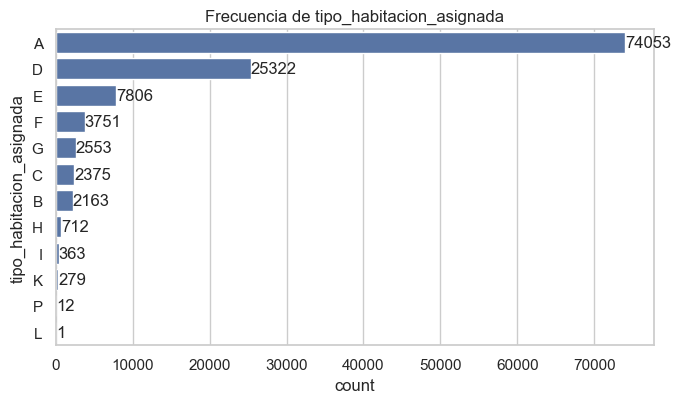

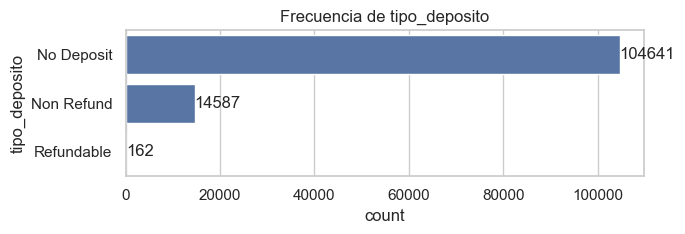

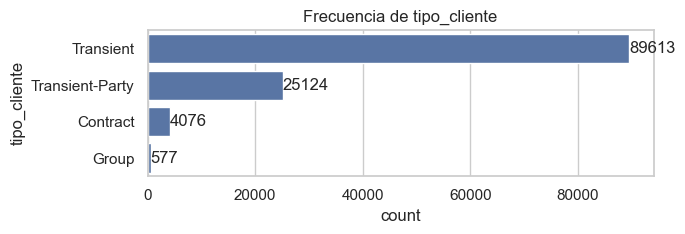

In [10]:
# ==========================================================
# 2. ESTADÍSTICAS (números y gráficos)
# ==========================================================
print('========================================')
print('2. ESTADÍSTICAS')
print('========================================\n')

# ---------- Listas de columnas ----------
num_cols = ['dias_anticipacion', 'anio_llegada', 'semana_llegada', 'dia_llegada',
            'noches_fin_semana', 'noches_entre_semana', 'adultos', 'ninos', 'bebes',
            'es_huesped_repetido', 'cancelaciones_previas', 'reservas_previas_no_canceladas',
            'cambios_reserva', 'dias_lista_espera', 'tarifa_diaria',
            'espacios_parqueadero', 'solicitudes_especiales']

cat_cols = ['hotel', 'mes_llegada', 'comida', 'pais', 'segmento_mercado',
            'canal_distribucion', 'tipo_habitacion_reservada', 'tipo_habitacion_asignada',
            'tipo_deposito', 'tipo_cliente']

# ---------- 2.1 NÚMEROS: variables numéricas ----------
print('--- 2.1 Estadísticos de las variables numéricas ---')
resumen = df[num_cols].describe().T
resumen['mediana'] = df[num_cols].median()
resumen['IQR'] = df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25)
resumen['asimetria'] = df[num_cols].skew().round(2)
resumen['curtosis'] = df[num_cols].kurt().round(2)
resumen['ceros_%'] = ((df[num_cols] == 0).mean() * 100).round(1)
display(resumen.round(2))

# ---------- 2.2 NÚMEROS: variables categóricas ----------
print('\n--- 2.2 Variables categóricas: categorías, moda y dominancia ---')
filas = []
for c in cat_cols:
    frec = df[c].value_counts(normalize=True)
    filas.append({'variable': c,
                  'categorias': df[c].nunique(),
                  'moda': frec.index[0],
                  'dominancia_%': round(frec.iloc[0] * 100, 1)})
print(pd.DataFrame(filas).to_string(index=False))

print('\n--- Frecuencias de algunas categóricas clave ---')
for c in ['hotel', 'tipo_deposito', 'tipo_cliente', 'comida', 'segmento_mercado']:
    print(f'\n{c}:')
    print(pd.DataFrame({
        'frecuencia': df[c].value_counts(),
        'porcentaje_%': (df[c].value_counts(normalize=True) * 100).round(2)
    }))

# ---------- 2.3 NÚMEROS: variable objetivo ----------
print('\n--- 2.3 Variable objetivo: es_cancelado ---')
conteo = df[objetivo].value_counts()
prop = df[objetivo].value_counts(normalize=True)
print(pd.DataFrame({'conteo': conteo, 'proporcion_%': (prop * 100).round(2)}))
print(f'Razón de desbalance: {conteo.max() / conteo.min():.2f} : 1')
print(f'Accuracy de referencia (siempre predecir la clase mayoritaria): {prop.max():.1%}')

# ---------- 2.4 NÚMEROS: atípicos por el método IQR ----------
print('\n--- 2.4 Valores atípicos (criterio 1.5·IQR) ---')
filas = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[c] < li) | (df[c] > ls)).sum()
    filas.append({'variable': c, 'lim_inf': round(li, 2), 'lim_sup': round(ls, 2),
                  'atipicos': n, 'atipicos_%': round(n / df[c].notna().sum() * 100, 2)})
print(pd.DataFrame(filas).sort_values('atipicos_%', ascending=False).to_string(index=False))

# ---------- 2.5 GRÁFICOS: variable objetivo ----------
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x=objetivo, ax=axes[0])
axes[0].set_title('Cantidad por clase (0 = no canceló, 1 = canceló)')
axes[1].pie(conteo.sort_index(), labels=['No canceló (0)', 'Canceló (1)'], autopct='%1.1f%%')
axes[1].set_title('Proporción de clases')
plt.tight_layout()
plt.show()

# ---------- 2.6 GRÁFICOS: histogramas de las numéricas ----------
df[num_cols].hist(bins=30, figsize=(16, 12), layout=(-1, 4))
plt.suptitle('Histogramas de las variables numéricas', y=1.01)
plt.tight_layout()
plt.show()

# ---------- 2.7 GRÁFICOS: boxplots de las numéricas continuas o con cola ----------
cols_box = ['dias_anticipacion', 'tarifa_diaria', 'noches_fin_semana', 'noches_entre_semana',
            'adultos', 'dias_lista_espera', 'cancelaciones_previas', 'cambios_reserva']
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), cols_box):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

# ---------- 2.8 GRÁFICOS: variables categóricas ----------
for c in cat_cols:
    orden = df[c].value_counts().head(15).index      # máximo 15 categorías (pais tiene ~178)
    plt.figure(figsize=(7, max(2.5, 0.35 * len(orden))))
    ax = sns.countplot(data=df, y=c, order=orden)
    ax.bar_label(ax.containers[0], fmt='%d')
    plt.title(f'Frecuencia de {c}' + (' (15 más frecuentes)' if df[c].nunique() > 15 else ''))
    plt.tight_layout()
    plt.show()

                                                                                    Fin del analisis 

## 1. Información y EDA sobre el dataset

Una vez tenemos los datos cargados en memoria, vamos a obtener información sobre los mismos.

**Pregunta 1.1** ¿Cuántas filas y columnas tiene tu dataset? ¿Cuáles son los tipos de datos de cada columna?

In [12]:
# ==========================================================
# PREGUNTA 1.1: filas, columnas y tipos de datos
# ==========================================================
print('Filas:', df.shape[0])
print('Columnas:', df.shape[1])
print('\nResumen de dtypes:')
print(df.dtypes.value_counts())

# Tipo estadístico de cada columna (clasificación según la sección 2 de la guía)
tipo_estadistico = {
    'hotel': 'Binaria',
    'es_cancelado': 'Binaria (Target)',
    'dias_anticipacion': 'Continua',
    'anio_llegada': 'Fecha (año)',
    'mes_llegada': 'Cíclica (nominal)',
    'semana_llegada': 'Fecha / Cíclica',
    'dia_llegada': 'Fecha (día del mes)',
    'noches_fin_semana': 'Discreta',
    'noches_entre_semana': 'Discreta',
    'adultos': 'Discreta',
    'ninos': 'Discreta',
    'bebes': 'Discreta',
    'comida': 'Nominal',
    'pais': 'Nominal (alta cardinalidad)',
    'segmento_mercado': 'Nominal',
    'canal_distribucion': 'Nominal',
    'es_huesped_repetido': 'Binaria',
    'cancelaciones_previas': 'Discreta',
    'reservas_previas_no_canceladas': 'Discreta',
    'tipo_habitacion_reservada': 'Nominal',
    'tipo_habitacion_asignada': 'Nominal',
    'cambios_reserva': 'Discreta',
    'tipo_deposito': 'Nominal',
    'agente': 'Código de entidad (alta cardinalidad)',
    'empresa': 'Código de entidad (alta cardinalidad)',
    'dias_lista_espera': 'Discreta',
    'tipo_cliente': 'Nominal',
    'tarifa_diaria': 'Continua',
    'espacios_parqueadero': 'Discreta',
    'solicitudes_especiales': 'Discreta',
    'estado_reserva': 'Nominal (fuga de información)',
    'fecha_estado_reserva': 'Fecha (fuga de información)',
}

inventario = pd.DataFrame({
    'Dtype (Pandas)': df.dtypes.astype(str),
    'Tipo Estadístico (Guía)': pd.Series(tipo_estadistico),
    'Nulos (%)': (df.isna().mean() * 100).round(1),
    'Únicos': df.nunique(),
    'Ejemplos': [df[c].dropna().unique()[:3].tolist() for c in df.columns],
})

display(inventario)

print('\nResumen por tipo estadístico:')
print(inventario['Tipo Estadístico (Guía)'].value_counts().to_string())

Filas: 119390
Columnas: 32

Resumen de dtypes:
int64      16
object     12
float64     4
Name: count, dtype: int64


,Dtype (Pandas),Tipo Estadístico (Guía),Nulos (%),Únicos,Ejemplos
hotel,object,Binaria,0.0,2,"[Resort Hotel, City Hotel]"
es_cancelado,int64,Binaria (Target),0.0,2,"[0, 1]"
dias_anticipacion,int64,Continua,0.0,479,"[342, 737, 7]"
anio_llegada,int64,Fecha (año),0.0,3,"[2015, 2016, 2017]"
mes_llegada,object,Cíclica (nominal),0.0,12,"[July, August, September]"
semana_llegada,int64,Fecha / Cíclica,0.0,53,"[27, 28, 29]"
dia_llegada,int64,Fecha (día del mes),0.0,31,"[1, 2, 3]"
noches_fin_semana,int64,Discreta,0.0,17,"[0, 1, 2]"
noches_entre_semana,int64,Discreta,0.0,35,"[0, 1, 2]"
adultos,int64,Discreta,0.0,14,"[2, 1, 3]"



Resumen por tipo estadístico:
Tipo Estadístico (Guía)
Discreta                                 11
Nominal                                   7
Código de entidad (alta cardinalidad)     2
Continua                                  2
Binaria                                   2
Cíclica (nominal)                         1
Fecha (año)                               1
Binaria (Target)                          1
Fecha (día del mes)                       1
Fecha / Cíclica                           1
Nominal (alta cardinalidad)               1
Nominal (fuga de información)             1
Fecha (fuga de información)               1


*Tu respuesta a la pregunta 1.1 aquí: El dataset tiene 119.390 filas y 32 columnas. Hay columnas de tipo entero (int64), decimal (float64) y texto (object), como hotel, meal y country.*

**Pregunta 1.2** Realiza una exploración de las variables. Describe en qué consiste un ejemplo del dataset (una fila) y cuál es la variable objetivo (la que queremos predecir).

--- Una fila del dataset (una reserva) ---
hotel                             Resort Hotel
es_cancelado                                 0
dias_anticipacion                          342
anio_llegada                              2015
mes_llegada                               July
semana_llegada                              27
dia_llegada                                  1
noches_fin_semana                            0
noches_entre_semana                          0
adultos                                      2
ninos                                      0.0
bebes                                        0
comida                                      BB
pais                                       PRT
segmento_mercado                        Direct
canal_distribucion                      Direct
es_huesped_repetido                          0
cancelaciones_previas                        0
reservas_previas_no_canceladas               0
tipo_habitacion_reservada                    C
tipo_habitacion_a

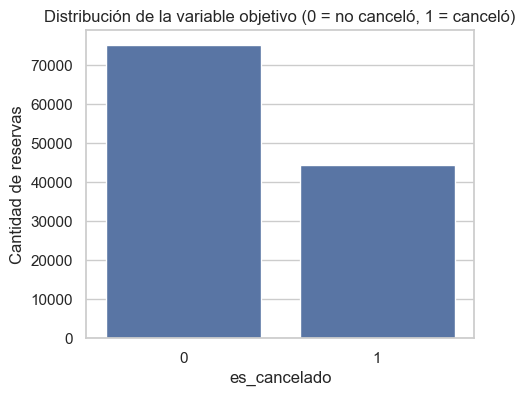

In [13]:
# ==========================================================
# PREGUNTA 1.2: una fila del dataset y la variable objetivo
# ==========================================================
print('--- Una fila del dataset (una reserva) ---')
print(df.iloc[0].to_string())

print('\n--- Variable objetivo: es_cancelado ---')
print('Tipo de dato:', df[objetivo].dtype)
print('Valores únicos:', sorted(df[objetivo].unique()))
print()
print(pd.DataFrame({
    'conteo': df[objetivo].value_counts(),
    'porcentaje_%': (df[objetivo].value_counts(normalize=True) * 100).round(2)
}))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x=objetivo)
plt.title('Distribución de la variable objetivo (0 = no canceló, 1 = canceló)')
plt.xlabel('es_cancelado')
plt.ylabel('Cantidad de reservas')
plt.show()

*Tu respuesta a la pregunta 1.2 aquí:
Cada registro del dataset representa **una reserva de hotel**. Una misma fila recopila toda la información relacionada con esa reserva:

- **Datos de la estadía:** hotel (Resort o City Hotel), fecha de llegada (año, mes, semana y día), noches de fin de semana y entre semana.
- **Datos de los huéspedes:** número de adultos, niños y bebés, país de origen, tipo de cliente y si es huésped repetido.
- **Datos de la reserva:** días de anticipación con que se reservó, canal de distribución, segmento de mercado, agente o empresa, tipo de comida, tipo de habitación reservada y asignada, tipo de depósito, cambios realizados y días en lista de espera.
- **Datos económicos y solicitudes:** tarifa diaria promedio, espacios de parqueadero requeridos y número de solicitudes especiales.
- **Historial:** cancelaciones previas y reservas previas no canceladas.

La variable objetivo (*target*) es la columna **`es_cancelado`**.

- **Valores que toma:** es una variable binaria numérica: **1** si la reserva fue cancelada y **0** si no lo fue.
- **Propósito:** es la etiqueta que nuestra red neuronal intentará predecir. A partir de las demás variables de entrada (*features*), el modelo aprenderá qué combinación de factores hace que una reserva termine cancelada o no.
- **Balance:** aproximadamente 63 % de las reservas no fueron canceladas y 37 % sí (verifica con tu salida).*

**Pregunta 1.3** Analiza la correlación entre Variables Numéricas.
Calcula la matriz de correlación para las variables numéricas de tu dataset. Para una mejor interpretación, visualiza esta matriz usando un mapa de calor (heatmap).

* ¿Identificas alguna variable que esté fuertemente correlacionada (positiva o negativamente) con la variable objetivo?
* ¿Existen pares de variables predictoras que estén fuertemente correlacionadas entre sí? ¿Qué problema podría causar esto?

*Pista: Utiliza el método .corr() de Pandas y la función sns.heatmap() de Seaborn para la visualización.*

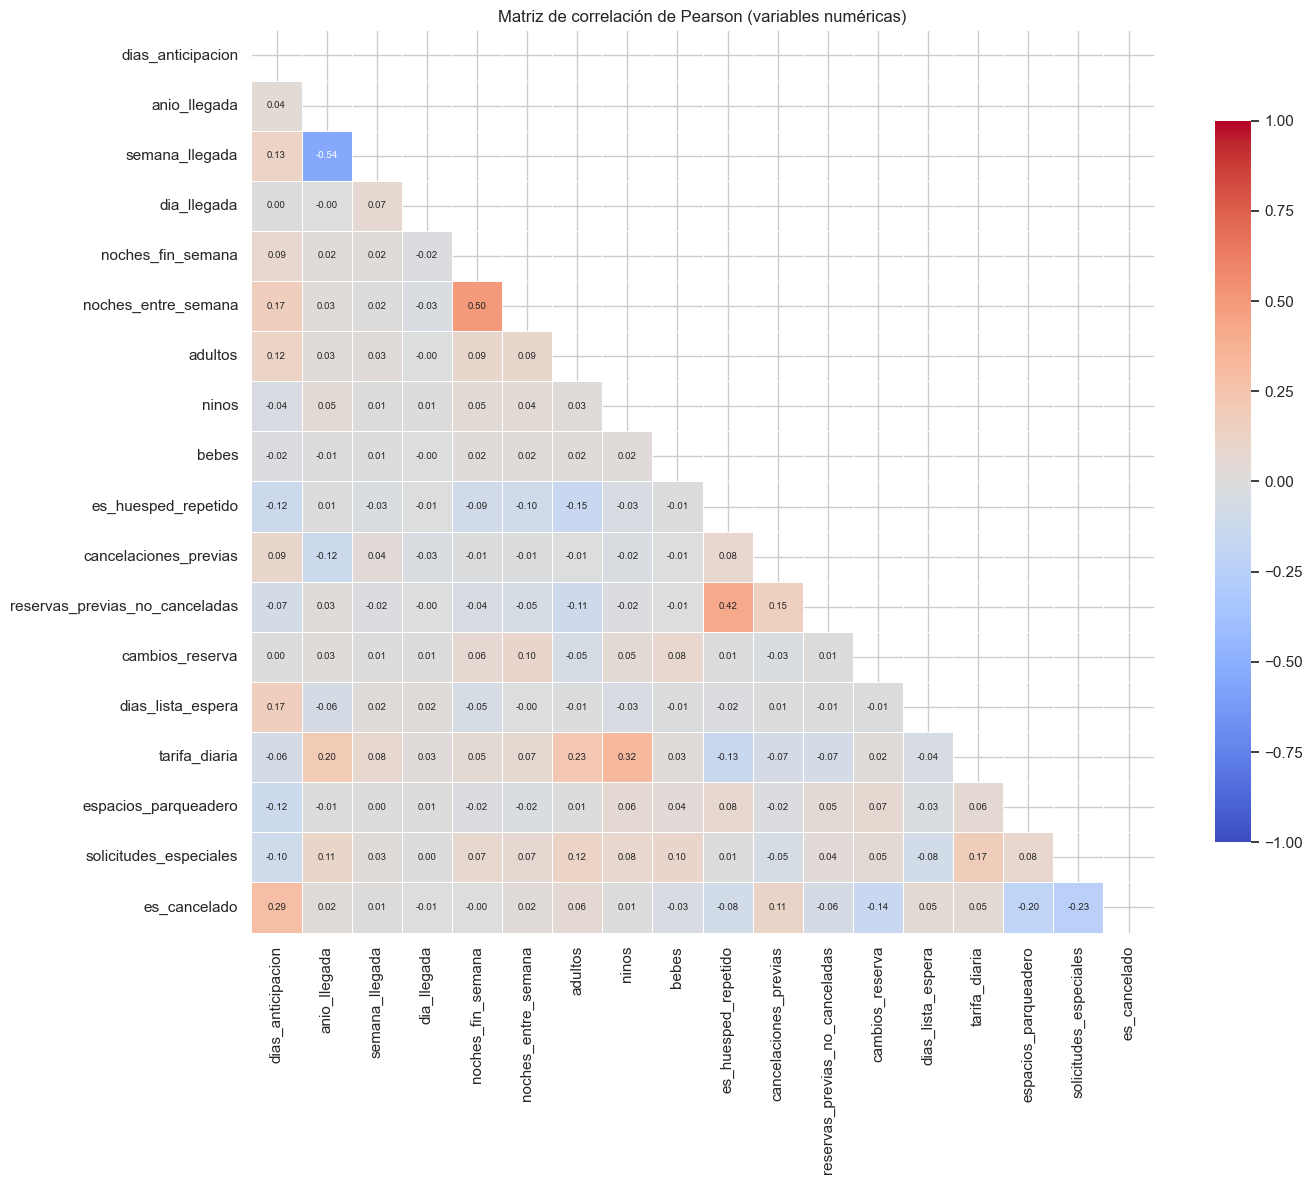

--- Correlación con es_cancelado (ordenada por fuerza) ---
dias_anticipacion                 0.293
solicitudes_especiales           -0.235
espacios_parqueadero             -0.195
cambios_reserva                  -0.144
cancelaciones_previas             0.110
es_huesped_repetido              -0.085
adultos                           0.060
reservas_previas_no_canceladas   -0.057
dias_lista_espera                 0.054
tarifa_diaria                     0.048
bebes                            -0.032
noches_entre_semana               0.025
anio_llegada                      0.017
semana_llegada                    0.008
dia_llegada                      -0.006
ninos                             0.005
noches_fin_semana                -0.002


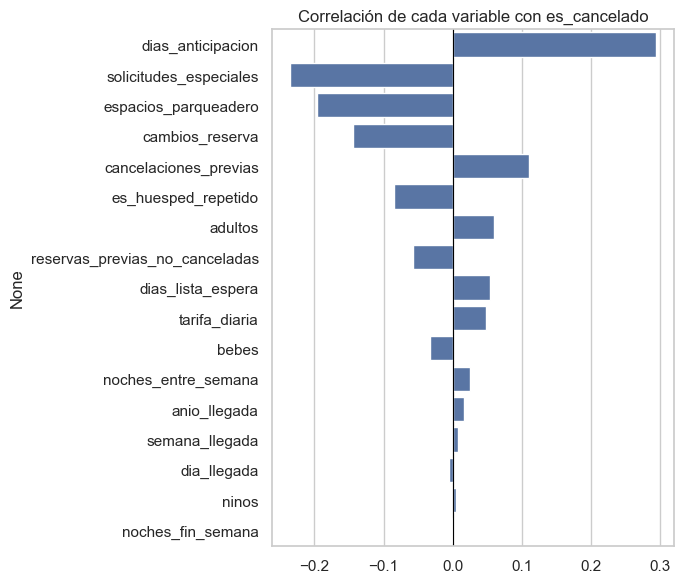


--- Pares de predictoras con |r| > 0.3 ---
anio_llegada         semana_llegada                   -0.541
noches_fin_semana    noches_entre_semana               0.499
es_huesped_repetido  reservas_previas_no_canceladas    0.418
ninos                tarifa_diaria                     0.325

--- Pearson vs. Spearman con es_cancelado (top 6) ---
                        pearson  spearman
dias_anticipacion         0.293     0.317
solicitudes_especiales   -0.235    -0.259
espacios_parqueadero     -0.195    -0.197
cambios_reserva          -0.144    -0.185
cancelaciones_previas     0.110     0.270
es_huesped_repetido      -0.085    -0.085


In [20]:
# ==========================================================
# PREGUNTA 1.3: correlación entre variables numéricas
# ==========================================================
num_cols = ['dias_anticipacion', 'anio_llegada', 'semana_llegada', 'dia_llegada',
            'noches_fin_semana', 'noches_entre_semana', 'adultos', 'ninos', 'bebes',
            'es_huesped_repetido', 'cancelaciones_previas', 'reservas_previas_no_canceladas',
            'cambios_reserva', 'dias_lista_espera', 'tarifa_diaria',
            'espacios_parqueadero', 'solicitudes_especiales']

# ---------- 1. Matriz de correlación + heatmap (incluye el objetivo) ----------
cols_corr = num_cols + [objetivo]
corr = df[cols_corr].corr(method='pearson')

mascara = np.triu(np.ones_like(corr, dtype=bool))      # oculta el triángulo repetido
plt.figure(figsize=(15, 12))
sns.heatmap(corr, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            annot_kws={'size': 7}, cbar_kws={'shrink': 0.8})
plt.title('Matriz de correlación de Pearson (variables numéricas)')
plt.tight_layout()
plt.show()

# ---------- 2. Correlación de cada variable con el objetivo ----------
print('--- Correlación con es_cancelado (ordenada por fuerza) ---')
corr_obj = corr[objetivo].drop(objetivo).sort_values(key=abs, ascending=False)
print(corr_obj.round(3).to_string())

plt.figure(figsize=(7, 6))
sns.barplot(x=corr_obj.values, y=corr_obj.index, orient='h')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlación de cada variable con es_cancelado')
plt.tight_layout()
plt.show()

# ---------- 3. Pares de predictoras correlacionadas entre sí ----------
print('\n--- Pares de predictoras con |r| > 0.3 ---')
corr_pred = df[num_cols].corr()
pares = (corr_pred.where(np.triu(np.ones(corr_pred.shape, dtype=bool), k=1))
                  .stack()
                  .rename('r'))
pares = pares[pares.abs() > 0.3].sort_values(key=abs, ascending=False)
print(pares.round(3).to_string() if len(pares) else 'Ningún par supera 0.3')

# ---------- 4. Comparación con Spearman (por los atípicos) ----------
print('\n--- Pearson vs. Spearman con es_cancelado (top 6) ---')
spear = df[num_cols].corrwith(df[objetivo], method='spearman')
comp = pd.DataFrame({'pearson': corr_obj, 'spearman': spear[corr_obj.index]})
print(comp.head(6).round(3))

*Tu respuesta a la pregunta 1.3 aquí:“La variable más correlacionada con is_canceled es lead_time (r = 0.293), aunque la relación es moderada. Entre las predictoras, los pares más correlacionados son arrival_date_year y arrival_date_week_number (r = 0.540561). Esto puede causar multicolinealidad, que genera redundancia y pesos inestables en el modelo.” *

**Pregunta 1.4** Visualización de Características Clave vs. Variable Objetivo
Elige una variable numérica que consideres importante (ej. 'edad', 'antigüedad', 'saldo') y una variable categórica clave (ej. 'geografía', 'género', 'tipo_de_contrato') para analizar su relación con la variable objetivo.

* Para la variable numérica, crea un boxplot o un histograma que compare su distribución para cada una de las clases de la variable objetivo (por ejemplo, la distribución de la 'antigüedad' para los clientes que abandonan vs. los que no).

* Para la variable categórica, utiliza un gráfico de barras agrupado (countplot con el parámetro hue) para mostrar cómo se distribuye la variable objetivo dentro de cada categoría.

* Analiza ambas gráficas y describe cualquier patrón o diferencia interesante que observes.

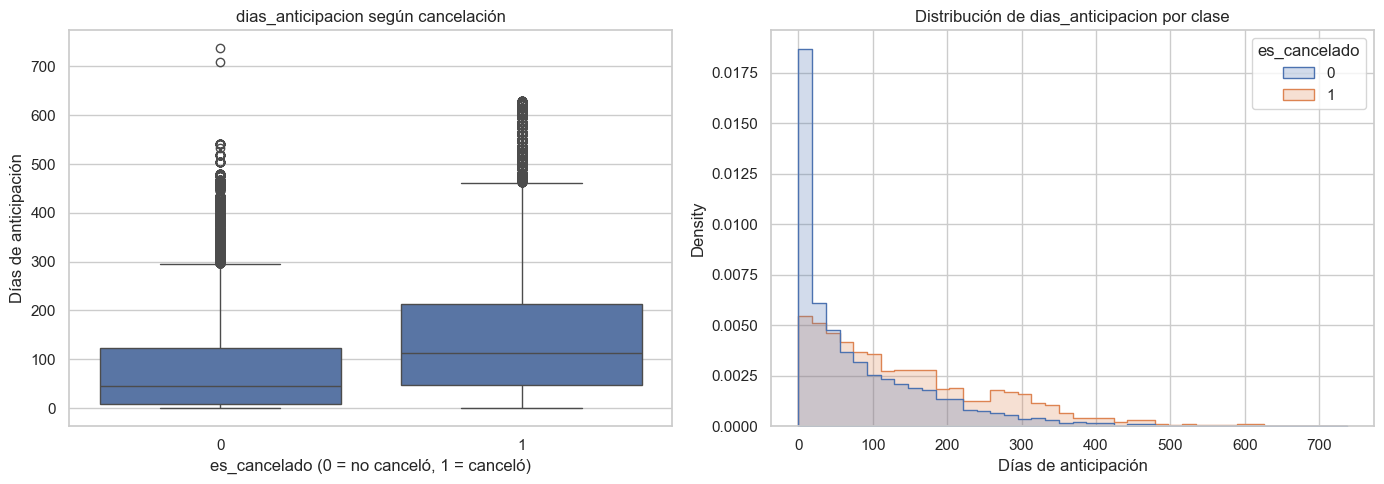

--- Estadísticos de dias_anticipacion por clase ---
                count   mean    std  min   25%    50%    75%    max
es_cancelado                                                       
0             75166.0   80.0   91.1  0.0   9.0   45.0  124.0  737.0
1             44224.0  144.8  118.6  0.0  48.0  113.0  214.0  629.0


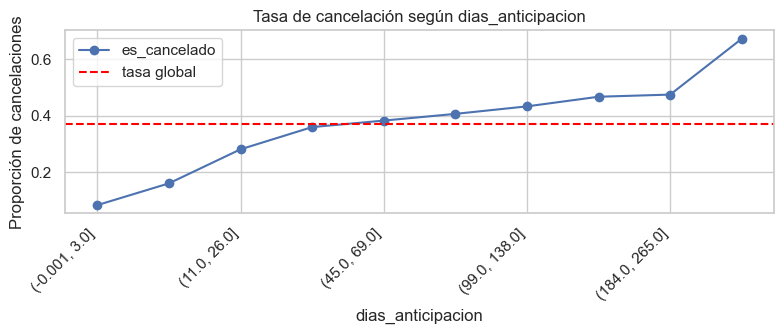

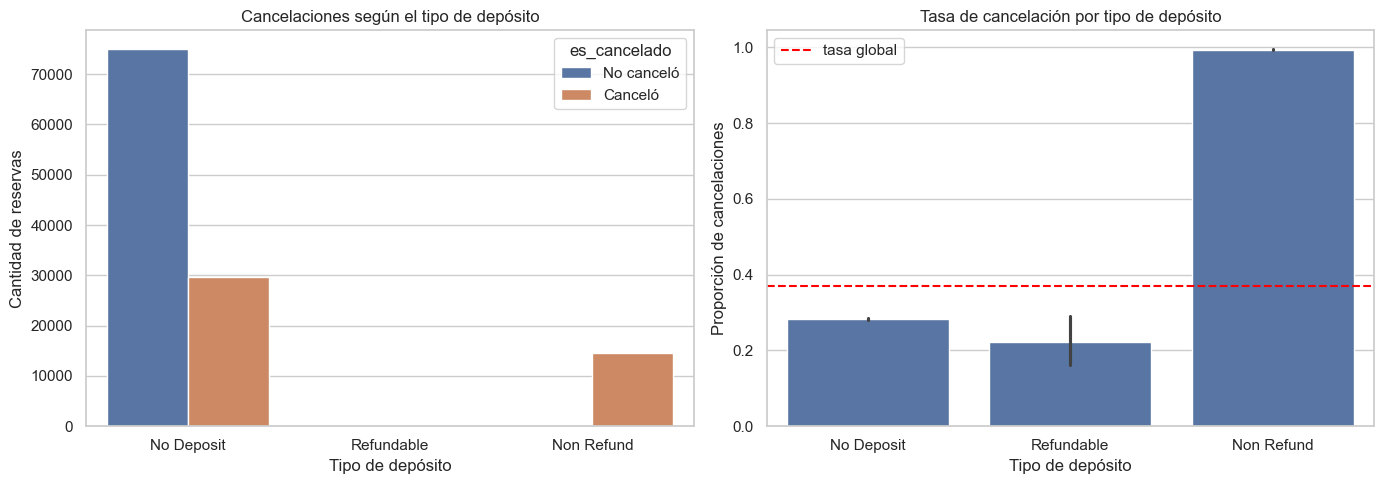

--- Tasa de cancelación por tipo_deposito ---
               reservas  tasa_cancelacion
tipo_deposito                            
No Deposit       104641             0.284
Non Refund        14587             0.994
Refundable          162             0.222


In [22]:
# ==========================================================
# PREGUNTA 1.4: características clave vs. variable objetivo
# ==========================================================
tasa_global = df[objetivo].mean()

# ---------- 1. Variable numérica: dias_anticipacion (boxplot + histograma) ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x=objetivo, y='dias_anticipacion', ax=axes[0])
axes[0].set_title('dias_anticipacion según cancelación')
axes[0].set_xlabel('es_cancelado (0 = no canceló, 1 = canceló)')
axes[0].set_ylabel('Días de anticipación')

sns.histplot(data=df, x='dias_anticipacion', hue=objetivo, bins=40,
             stat='density', common_norm=False, element='step', ax=axes[1])
axes[1].set_title('Distribución de dias_anticipacion por clase')
axes[1].set_xlabel('Días de anticipación')

plt.tight_layout()
plt.show()

print('--- Estadísticos de dias_anticipacion por clase ---')
print(df.groupby(objetivo)['dias_anticipacion'].describe().round(1))

# ---------- 2. Tasa de cancelación por intervalos (deciles) ----------
intervalos = pd.qcut(df['dias_anticipacion'], q=10, duplicates='drop')
tasa = df.groupby(intervalos, observed=True)[objetivo].mean()

plt.figure(figsize=(8, 3.5))
tasa.plot(marker='o')
plt.axhline(tasa_global, color='red', linestyle='--', label='tasa global')
plt.ylabel('Proporción de cancelaciones')
plt.xticks(rotation=45, ha='right')
plt.title('Tasa de cancelación según dias_anticipacion')
plt.legend()
plt.tight_layout()
plt.show()

# ---------- 3. Variable categórica: tipo_deposito (countplot con hue) ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='tipo_deposito', hue=objetivo, ax=axes[0])
axes[0].set_title('Cancelaciones según el tipo de depósito')
axes[0].set_xlabel('Tipo de depósito')
axes[0].set_ylabel('Cantidad de reservas')
axes[0].legend(title='es_cancelado', labels=['No canceló', 'Canceló'])

# Como "No Deposit" domina en cantidad, se muestra también la tasa por categoría
sns.barplot(data=df, x='tipo_deposito', y=objetivo, ax=axes[1])
axes[1].axhline(tasa_global, color='red', linestyle='--', label='tasa global')
axes[1].set_title('Tasa de cancelación por tipo de depósito')
axes[1].set_xlabel('Tipo de depósito')
axes[1].set_ylabel('Proporción de cancelaciones')
axes[1].legend()

plt.tight_layout()
plt.show()

print('--- Tasa de cancelación por tipo_deposito ---')
print(df.groupby('tipo_deposito')[objetivo].agg(['size', 'mean']).round(3)
        .rename(columns={'size': 'reservas', 'mean': 'tasa_cancelacion'}))

*Tu respuesta a la pregunta 1.4: Las reservas canceladas tienen en promedio mucha más anticipación (lead_time) que las no canceladas, lo que sugiere que a mayor tiempo entre la reserva y la llegada, mayor probabilidad de cancelar. En cuanto al tipo de depósito, la categoría Non Refund presenta una tasa de cancelación muy superior a las demás, un patrón inesperado que podría deberse a ... Ambas variables parecen aportar información útil para el modelo.*

In [4]:
# ==========================================================
# PLUS: TABLA RESUMEN DEL EDA (plantilla 11.3 de la guía)
# ==========================================================
from scipy.stats import chi2_contingency

# ---------- Tipo estadístico (sección 2 de la guía) ----------
tipo = {
    'hotel': 'Binaria', 'es_cancelado': 'Binaria (Target)',
    'dias_anticipacion': 'Continua', 'anio_llegada': 'Fecha (año)',
    'mes_llegada': 'Cíclica', 'semana_llegada': 'Fecha / cíclica',
    'dia_llegada': 'Fecha (día)', 'noches_fin_semana': 'Discreta',
    'noches_entre_semana': 'Discreta', 'adultos': 'Discreta', 'ninos': 'Discreta',
    'bebes': 'Discreta', 'comida': 'Nominal', 'pais': 'Nominal',
    'segmento_mercado': 'Nominal', 'canal_distribucion': 'Nominal',
    'es_huesped_repetido': 'Binaria', 'cancelaciones_previas': 'Discreta',
    'reservas_previas_no_canceladas': 'Discreta',
    'tipo_habitacion_reservada': 'Nominal', 'tipo_habitacion_asignada': 'Nominal',
    'cambios_reserva': 'Discreta', 'tipo_deposito': 'Nominal',
    'agente': 'Código de entidad', 'empresa': 'Código de entidad',
    'dias_lista_espera': 'Discreta', 'tipo_cliente': 'Nominal',
    'tarifa_diaria': 'Continua', 'espacios_parqueadero': 'Discreta',
    'solicitudes_especiales': 'Discreta', 'estado_reserva': 'Nominal',
    'fecha_estado_reserva': 'Fecha',
}

# ---------- Decisión de preprocesado (edítala con tu criterio) ----------
decision = {
    'hotel': 'One-Hot (binaria 0/1)',
    'es_cancelado': 'Conservar como objetivo (ya es 0/1)',
    'dias_anticipacion': 'Log1p opcional; escalar con MinMaxScaler',
    'anio_llegada': 'Escalar; riesgoso con datos futuros',
    'mes_llegada': 'One-Hot (o seno/coseno)',
    'semana_llegada': 'Escalar',
    'dia_llegada': 'Escalar (aporta poco)',
    'noches_fin_semana': 'Escalar; revisar atípicos',
    'noches_entre_semana': 'Escalar; revisar atípicos',
    'adultos': 'Eliminar filas imposibles (0 huéspedes); escalar',
    'ninos': 'Imputar con 0; escalar',
    'bebes': 'Casi constante: conservar o eliminar; escalar',
    'comida': 'Unir Undefined con SC; One-Hot',
    'pais': 'Imputar "Desconocido"; agrupar raros en "Otro"; One-Hot',
    'segmento_mercado': 'One-Hot',
    'canal_distribucion': 'One-Hot',
    'es_huesped_repetido': 'Conservar (ya es 0/1)',
    'cancelaciones_previas': 'Escalar; considerar indicador > 0',
    'reservas_previas_no_canceladas': 'Escalar',
    'tipo_habitacion_reservada': 'One-Hot',
    'tipo_habitacion_asignada': 'One-Hot; posible fuga leve, revisar',
    'cambios_reserva': 'Escalar',
    'tipo_deposito': 'One-Hot; vigilar Non Refund',
    'agente': 'Convertir en indicador tiene_agente (0/1)',
    'empresa': 'Convertir en indicador tiene_empresa (0/1)',
    'dias_lista_espera': 'Casi constante; escalar o eliminar',
    'tipo_cliente': 'One-Hot',
    'tarifa_diaria': 'Quitar valor extremo y negativos; escalar',
    'espacios_parqueadero': 'Escalar',
    'solicitudes_especiales': 'Escalar',
    'estado_reserva': 'ELIMINAR (fuga de información)',
    'fecha_estado_reserva': 'ELIMINAR (fuga de información)',
}

fuga = ['estado_reserva', 'fecha_estado_reserva']

# ---------- Funciones de apoyo ----------
def cramers_v(x, y):
    t = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(t, correction=False)
    return np.sqrt(chi2 / (t.to_numpy().sum() * (min(t.shape) - 1)))

def fuerza_corr(r):
    a = abs(r)
    return 'Despreciable' if a < 0.1 else 'Débil' if a < 0.3 else 'Moderada' if a < 0.5 else 'Fuerte'

def fuerza_v(v):
    return 'Despreciable' if v < 0.1 else 'Débil' if v < 0.2 else 'Moderada' if v < 0.4 else 'Fuerte'

# ---------- Construcción de la tabla ----------
filas = []
for c in df.columns:
    if c == objetivo:
        continue
    es_num = pd.api.types.is_numeric_dtype(df[c])
    problemas = []

    # Problemas detectados automáticamente
    if c in fuga:
        problemas.append('Fuga de información')
    if es_num:
        if abs(df[c].skew()) > 1:
            problemas.append(f'Asimetría {"positiva" if df[c].skew() > 0 else "negativa"} fuerte')
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        pct_at = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).mean() * 100
        if pct_at > 5:
            problemas.append(f'{pct_at:.0f} % atípicos')
        pct_cero = (df[c] == 0).mean() * 100
        if pct_cero > 90:
            problemas.append(f'{pct_cero:.0f} % ceros (casi constante)')
    else:
        n_cat = df[c].nunique()
        if n_cat > 15:
            problemas.append(f'Alta cardinalidad ({n_cat})')
        dom = df[c].value_counts(normalize=True).iloc[0] * 100
        if dom > 90:
            problemas.append(f'Dominancia {dom:.0f} %')

    # Relación con el objetivo
    if es_num:
        r = df[c].corr(df[objetivo])
        relacion = f'{fuerza_corr(r)} (r = {r:+.2f})'
    else:
        v = cramers_v(df[c].fillna('faltante'), df[objetivo])
        relacion = f'{fuerza_v(v)} (V = {v:.2f})'

    filas.append({
        'Variable': c,
        'Tipo': tipo.get(c, '—'),
        'Nulos (%)': round(df[c].isna().mean() * 100, 1),
        'Atípicos / problemas': '; '.join(problemas) if problemas else '—',
        'Relación con el objetivo': relacion,
        'Decisión de preprocesado': decision.get(c, '—'),
    })

resumen_eda = pd.DataFrame(filas)
display(resumen_eda)

# Opcional: guardar para anexar al informe
resumen_eda.to_csv('../resumen_eda.csv', index=False, encoding='utf-8-sig')

,Variable,Tipo,Nulos (%),Atípicos / problemas,Relación con el objetivo,Decisión de preprocesado
0,hotel,Binaria,0.0,—,Débil (V = 0.14),One-Hot (binaria 0/1)
1,dias_anticipacion,Continua,0.0,Asimetría positiva fuerte,Débil (r = +0.29),Log1p opcional; escalar con MinMaxScaler
2,anio_llegada,Fecha (año),0.0,—,Despreciable (r = +0.02),Escalar; riesgoso con datos futuros
3,mes_llegada,Cíclica,0.0,—,Despreciable (V = 0.07),One-Hot (o seno/coseno)
4,semana_llegada,Fecha / cíclica,0.0,—,Despreciable (r = +0.01),Escalar
5,dia_llegada,Fecha (día),0.0,—,Despreciable (r = -0.01),Escalar (aporta poco)
6,noches_fin_semana,Discreta,0.0,Asimetría positiva fuerte,Despreciable (r = -0.00),Escalar; revisar atípicos
7,noches_entre_semana,Discreta,0.0,Asimetría positiva fuerte,Despreciable (r = +0.02),Escalar; revisar atípicos
8,adultos,Discreta,0.0,Asimetría positiva fuerte; 25 % atípicos,Despreciable (r = +0.06),Eliminar filas imposibles (0 huéspedes); escalar
9,ninos,Discreta,0.0,Asimetría positiva fuerte; 7 % atípicos; 93 % ...,Despreciable (r = +0.01),Imputar con 0; escalar


## 2. Preprocesado de los datos

**Pregunta 2.1** Las redes neuronales trabajan con datos numéricos. Identifica las columnas con datos categóricos (texto) y conviértelas a un formato numérico. Una técnica común es **One-Hot Encoding**. Aplícala a las columnas que lo necesiten.

*Pista: La función `pd.get_dummies()` de Pandas es muy útil para esto.*

*Tu respuesta a la pregunta 2.1 aquí: Identifiqué las columnas categóricas con select_dtypes(include='object'): hotel, mes de llegada, tipo de comida, país, segmento de mercado, canal de distribución, tipo de habitación reservada y asignada, tipo de depósito y tipo de cliente. Antes de codificarlas eliminé reservation_status y reservation_status_date porque revelan directamente si la reserva fue cancelada (fuga de datos), y agrupé los países poco frecuentes en “Otro” para evitar cientos de columnas. Luego apliqué One-Hot Encoding con pd.get_dummies, lo que aumentó el número de columnas de X a Y.*

**Pregunta 2.2**: Analiza si existen valores nulos o faltantes en tu dataset. ¿En qué columnas aparecen y cuántos hay? ¿Cómo los tratarías?

*Tu respuesta a la pregunta 2.2: Sí existen valores nulos en cuatro columnas: company (≈94%), agent (≈14%), country (488 registros) y children (4 registros). En company y agent el nulo indica ausencia de empresa o agencia, por lo que las convertí en variables binarias (has_company, has_agent). En country imputé la categoría “Desconocido” y en children el valor 0, dado que son muy pocos casos. Tras el tratamiento no quedan nulos.*

**Pregunta 2.3** Para el entrenamiento de una red neuronal, es una buena práctica escalar las características numéricas para que todas tengan un rango similar (por ejemplo, entre 0 y 1). Este proceso se llama **normalización**. Aplica normalización a las columnas numéricas de tu dataset.

*Pista: `MinMaxScaler` y `StandardScaler()` de Scikit-learn son opciones para esta tarea. Elige una y explica por qué la elegiste*

*Tu respuesta a la pregunta 2.3 aquí: Elegí MinMaxScaler porque lleva todas las variables al rango [0, 1], igual que las columnas One-Hot, de modo que ninguna variable domina el entrenamiento por tener una escala mayor (por ejemplo lead_time frente a babies). Además funciona bien con activaciones como sigmoide y ReLU. La desventaja es su sensibilidad a valores atípicos, como los lead_time extremos, pero con el tamaño de este dataset el efecto es aceptable. StandardScaler también habría sido válido*

**Pregunta 2.4** Asegúrate de que tu variable objetivo (la columna a predecir) esté en formato numérico (0 y 1). Si está como texto (ej: 'Sí'/'No'), conviértela. Muestra cómo se ven algunas filas de tus datos después de todos los cambios. ¿Cómo crees que la red se beneficiará de estas transformaciones?

*Tu respuesta a la pregunta 2.4 aquí:
**Variable objetivo:** `is_canceled` ya está en formato numérico (`int64`) y solo toma los valores 0 (no canceló) y 1 (canceló), por lo que no necesitó conversión.

**Datos después de las transformaciones:** `X_train` tiene 95.512 filas y 81 variables, y `X_test` tiene 23.878 filas y 81 variables. No hay valores nulos, todas las columnas son numéricas y las variables continuas están normalizadas entre 0 y 1.

**¿Cómo se beneficia la red?**
- Solo procesa números: el One-Hot Encoding convirtió el texto en columnas 0/1.
- Entrena de forma más estable y rápida: al tener todas las variables en una escala similar, ninguna domina el entrenamiento por tener valores grandes (por ejemplo `lead_time` frente a `babies`).
- Evita errores: sin nulos no aparecen valores `NaN` durante el entrenamiento.
- Aprende patrones reales: al eliminar `reservation_status` y `reservation_status_date` se evitó la fuga de datos, y al ajustar el escalador solo con el entrenamiento, el conjunto de prueba mide de forma honesta el desempeño con datos nuevos.*

**Pregunta 2.5**: Analiza el balanceo de la variable objetivo. ¿Está balanceada la cantidad de clases (Ej. 0 y 1)? ¿Qué técnicas podrías aplicar si existe desbalance? Analiza al menos 3 opciones.


Técnicas para el desbalance (3 o más opciones)

1. Pesos de clase (class_weight). Se le dice a la red que un error en la clase minoritaria cuesta más. No modifica los datos.
Ventaja: simple, sin perder ni inventar datos.
Desventaja: puede aumentar los falsos positivos.
2. Sobremuestreo (oversampling), por ejemplo SMOTE. Se aumentan las muestras de la clase minoritaria, duplicándolas o generando sintéticas. Requiere pip install imbalanced-learn.

Ventaja: la red ve más ejemplos de la clase minoritaria.
Desventaja: riesgo de sobreajuste, y con 81 variables (muchas dummies) los ejemplos sintéticos pueden no ser realistas. Se aplica solo al entrenamiento, nunca al test.

3. Submuestreo (undersampling). Se eliminan filas de la clase mayoritaria hasta igualar.

Ventaja: entrenamiento más rápido y clases iguales.
Desventaja: se pierde información valiosa; con un desbalance moderado no compensa.

4. Ajustar el umbral de decisión. En lugar de clasificar como 1 si la probabilidad es > 0.5, se prueba otro umbral (por ejemplo 0.4) según lo que interese: más recall o más precisión.

5. Usar métricas adecuadas. Evaluar con F1, recall, matriz de confusión y AUC-ROC, y no solo accuracy.

*Tu respuesta a la pregunta 2.5 aquí:La variable objetivo no está perfectamente balanceada: aproximadamente 63% de las reservas no fueron canceladas y 37% sí, una razón cercana a 1.7:1. Es un desbalance moderado, no crítico. Si fuera necesario corregirlo, podría aplicar (1) pesos de clase en el entrenamiento, (2) sobremuestreo de la clase minoritaria con SMOTE, y (3) submuestreo de la clase mayoritaria. Además, evaluaría el modelo con F1, recall y matriz de confusión en lugar de solo la exactitud.*

**Pregunta 2.6**: ¿Detectas algún otro aspecto relevante de limpieza o preprocesado en los datos? Por ejemplo: valores atípicos, duplicados, escalas inconsistentes, o variables irrelevantes. Explica cómo lo abordarías.

*Tu respuesta a la pregunta 2.6 aquí:*Detecté varios aspectos adicionales: (1) filas duplicadas, que revisaría antes de eliminarlas porque el dataset no tiene identificador de reserva; (2) valores atípicos, como una tarifa adr de 5.400 y reservas con decenas de adultos, que limitaría con un umbral o percentil; (3) registros inconsistentes, como reservas con 0 huéspedes o 0 noches, que eliminaría; y (4) variables poco informativas o redundantes, como babies y days_in_waiting_list (casi todo ceros) y el par reserved_room_type/assigned_room_type, que podría resumirse en un indicador de cambio de habitación. El tratamiento de outliers debe hacerse antes de la normalización porque MinMaxScaler es sensible a ellos.

## 3. Creación del Modelo

Ahora vamos a definir el modelo. Repasemos algunos conceptos de Keras:
* **Sequential**: Define una SECUENCIA de capas en la red neuronal.
* **Dense**: Es una capa de neuronas totalmente conectada, el tipo de capa más común.

Cada capa necesita una **función de activación**. Usaremos:
* **ReLU** (Rectified Linear Unit) en las capas ocultas. Es eficiente y ayuda a mitigar problemas de gradientes.
* **Sigmoid** en la capa de salida. Devuelve un valor entre 0 y 1, ideal para representar la probabilidad en una clasificación binaria.

**Pregunta 3.1**. Antes de crear el modelo, divide tus datos en un conjunto de entrenamiento y un conjunto de prueba. Luego, define una red neuronal con las siguientes características:

* Una capa de entrada con el tamaño adecuado para tus datos.
* Una capa oculta con 16 neuronas y activación ReLU.
* Una capa de salida con 1 neurona y activación Sigmoid.

(65229, 79) (16308, 79)


**Pregunta 3.2**: Utiliza la función `summary()` para mostrar la estructura de tu modelo y explica qué representa la columna "Param #".

*Tu respuesta a la pregunta 3.2 aquí:*

## 4. Compilación y Entrenamiento

**Pregunta 4.1**: Compila tu modelo. Utiliza **`binary_crossentropy`** como función de pérdida, **`adam`** como optimizador, y monitoriza la **`accuracy`** durante el entrenamiento. Explica brevemente por qué `binary_crossentropy` es la función de pérdida adecuada para este problema.

*Tu respuesta a la pregunta 4.1 aquí:*

**Pregunta 4.2**: Utiliza la función `fit()` para entrenar tu modelo. Para este primer entrenamiento, utiliza los siguientes valores:
* `epochs = 20`
* `batch_size = 32`
* `validation_split = 0.2`

## 5. Impacto al variar el número de neuronas en las capas ocultas

Experimenta cambiando el número de neuronas en la capa oculta. Entrena dos nuevos modelos usando la misma configuración anterior, pero con:

* **8 neuronas en la capa oculta**
* **32 neuronas en la capa oculta**

In [ ]:
### Tu código para el modelo con 8 neuronas aquí ###


In [ ]:
### Tu código para el modelo con 32 neuronas aquí ###


**Pregunta 5.1**: ¿Cuál es el impacto en la precisión (accuracy) del modelo al usar menos o más neuronas? ¿Observas alguna diferencia en el tiempo de entrenamiento?

*Tu respuesta a la pregunta 5.1. aquí:*

## 6. Número de neuronas y función de activación de la capa de salida

Considera la capa final (de salida) de tu red neuronal.

**Pregunta 6.1**: ¿Por qué se utiliza 1 neurona en la última capa y por qué con activación Sigmoid?

*Tu respuesta a la pregunta 6.1 aquí:*

**Pregunta 6.2**: ¿Qué pasaría si intentaras usar 2 neuronas con activación `softmax` en la capa de salida? ¿Qué cambiarías en la compilación del modelo (especialmente en la función de pérdida) para que esto funcione?

In [ ]:
### Tu código aquí ###

*Tu respuesta a la pregunta 6.2 aquí:*

## 7. Aumento de `epochs` y su efecto en la red neuronal

En esta parte vamos a ver el impacto de aumentar las épocas en el entrenamiento. Usando el modelo original (con 16 neuronas en la capa oculta):

**Pregunta 7.1**: Entrena el modelo con `epochs = 100`.

In [ ]:
### Tu código para 100 epochs aquí ###


**Pregunta 7.2**: Compara la precisión y la pérdida final en los datos de entrenamiento y validación. ¿El rendimiento en la validación sigue mejorando hasta el final, o empieza a estancarse o empeorar? ¿Cómo se llama este fenómeno?

In [ ]:
### Tu código aquí ###

*Tu respuesta a la pregunta 7.2 aquí:*

## 8. Early Stopping (Parada Temprana)

En el ejercicio anterior, es posible que notaras que después de un cierto número de épocas el modelo dejaba de mejorar en los datos de validación. Entrenar de más puede ser ineficiente y llevar a sobreajuste.

**Pregunta 8.1**: Investiga y utiliza un `callback` de Keras llamado **`EarlyStopping`**. Configúralo para que monitorice la pérdida de validación (`val_loss`) y detenga el entrenamiento si no hay una mejora después de 10 épocas (`patience=10`). Vuelve a entrenar tu modelo con `epochs=100`. Realiza pruebas con diferentes épocas de *EarlyStopping* y describe tus observaciones concluyendo cuál debería ser el número adecuado y por qué.

In [ ]:
### Tu código aquí ###


*Tu respuesta a la pregunta 8.1 aquí:*

## 9. Unidades de activación

**Pregunta 9.1**: Vuelve a entrenar tu modelo original, pero esta vez cambia la función de activación de la capa oculta de `relu` a `sigmoid`. Compara el rendimiento (precisión y velocidad de convergencia) con el modelo que usaba ReLU. ¿Por qué crees que ReLU suele ser preferido en las capas ocultas?

In [ ]:
### Tu código y comentarios de texto aquí ###


*Tu respuesta a la pregunta 9.1 aquí:*

## 10. Inicialización de parámetros

**Pregunta 10.1**: La forma en que se inicializan los pesos de una red puede afectar el entrenamiento. Investiga cómo especificar la inicialización de pesos en una capa `Dense` de Keras. Entrena dos modelos nuevos:

* Uno con inicialización de todos los pesos a **ceros** (`kernel_initializer='zeros'`).
* Otro con inicialización **aleatoria normal** (`kernel_initializer='random_normal'`).

Compara los resultados con la inicialización por defecto de Keras (`glorot_uniform`). ¿Qué ocurre cuando inicializas todos los pesos a cero?

In [ ]:
### Tu código y comentarios de texto aquí ###


*Tu respuesta a la pregunta 10.1 aquí:*

## 11. Optimizadores

**Pregunta 11.1**: El optimizador `adam` es muy popular, pero existen otros. Entrena de nuevo tu modelo original, pero esta vez compilándolo con el optimizador **`SGD`** (Descenso de Gradiente Estocástico). Compara su rendimiento y velocidad de convergencia con `adam`. ¿Qué diferencias notas?

In [ ]:
### Tu código y comentarios de texto aquí ###


*Tu respuesta a la pregunta 11.1 aquí:*

## 12. Regularización y Red Final

**Pregunta 12.1**: Entrena una red final que combine lo que has aprendido. Tu objetivo es obtener el mejor rendimiento posible (>98% de precisión en el conjunto de validación y prueba) en el conjunto de prueba. Puedes experimentar con:

* Número de capas y neuronas.
* Optimizadores y su tasa de aprendizaje.
* Uso de regularización para evitar el sobreajuste, como **Dropout** (`tf.keras.layers.Dropout`).

Explica brevemente la estrategia que seguiste. Finalmente, evalúa tu modelo final sobre el conjunto de prueba (`X_test`, `y_test`) y muestra el **reporte de clasificación** y la **matriz de confusión**.

In [ ]:
### Tu modelo final y comentarios de texto aquí ###


*Tu respuesta a la pregunta 12.1 aquí:*